# Scam classifier: build a balanced dataset from the simulated calls and fine-tune PhayaThaiBERT

This notebook reads the simulated calls in `dataset/*.jsonl` (one file per call type), drops
the rejected ones, balances them, turns them into the record format from `docs/spec.html`, then trains and
scores two classifiers on them:

- the gate: scam or not scam
- the type: which of the 5 spec types, only for scam calls

The data is split into train, valid (validation) and test sets. The model learns from train,
valid picks the best epoch, and test is used once for the final scores.

Each task gets a TF-IDF + LogReg baseline and a fine-tuned PhayaThaiBERT
(`clicknext/phayathaibert`). All scores come from the test set. Charts are drawn with
matplotlib and seaborn.

| Part | Steps | Needs GPU |
|------|-------|-----------|
| A. Data preparation | 1 data loading, 2 EDA, 3 cleaning and preprocessing, 4 label mapping, 4b balancing, 5 near-duplicate detection, 6 train/valid/test split, 7 export | no |
| B. Modeling and evaluation | 8 baseline model, 9 tokenization, 10 train gate classifier, 11 train type classifier, 12 cross-validation, 13 evaluation (test set, recall by scam outcome, hand-written calls), 14 inference | yes |

Part B reads only the csv files that part A writes to `data/processed_balanced/`, so you can
rerun either part alone. The hand-written demo calls are never trained on. Step 13 reads their
cleaned copy, `data/processed/dataset.csv`, as an outside test.

## Setup

```
pip install torch --index-url https://download.pytorch.org/whl/cu128
pip install -e ".[ml]"
```

Install torch first. The default Windows wheel on PyPI is CPU only, and the RTX 50 series
needs the CUDA 12.8 build. Then pick the `.venv` kernel and run the cells top to bottom.

In [38]:
import json
import math
import random
import re
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Repo root is the nearest parent folder that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

# Part A writes the split here and part B reads it. The older data/processed/ (the hand-written
# demo split) is never read or written.
PROCESSED = ROOT / "data" / "processed_balanced"
MODELS = ROOT / "models"
CHECKPOINTS = ROOT / "checkpoints"

# Same values as nlp_core.types.SCAM_TYPES.
SCAM_TYPES = ("fake_authority", "romance", "investment", "phishing_otp", "lottery")

SPLIT_RATIOS = {"train": 0.70, "valid": 0.15, "test": 0.15}
NEAR_DUPLICATE_SIMILARITY = 0.70  # samples at or above this cosine similarity share a group
MIN_TYPE_SAMPLES = 15  # a scam type needs this many samples before the type model trains on it
MIN_TYPE_EVAL_SAMPLES = 5  # and this many in valid and in test, or its score is one or two answers

# False keeps the split already on disk. Set it to True after the dataset changes.
REBUILD_SPLIT = True

pd.set_option("display.max_colwidth", 200)

# Chart style. Each class and each model keeps one colour in every chart.
SURFACE, INK, MUTED, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#9a9992"
CLASS_COLORS = {"Not a Scam": "#2a78d6", "Scam": "#eb6834"}
MODEL_COLORS = {"tfidf_logreg": NEUTRAL, "phayathaibert": "#1baf7a"}
BLUES = LinearSegmentedColormap.from_list(
    "blues", [SURFACE, "#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"]
)
sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "axes.labelsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": False,
        "legend.fontsize": 9,
    },
)


def label_bars(ax, fmt: str = "{:.0f}") -> None:
    for bars in ax.containers:
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9, color=INK)


def table_heatmap(frame: pd.DataFrame, ax, fmt: str, **kwargs) -> None:
    """Draw a table as a grid of cells, darker for larger values."""
    sns.heatmap(
        frame,
        annot=True,
        fmt=fmt,
        cmap=BLUES,
        cbar=False,
        linewidths=2,
        linecolor=SURFACE,
        ax=ax,
        **kwargs,
    )
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)


print("repo root:", ROOT)

repo root: c:\Users\user\Documents\GitHub\Callas


# Part A. Data preparation

## Input format

The input is the simulated calls in `dataset/*.jsonl`: one JSON object per line, one file per
call type (fake_authority, investment, lottery, normal, phishing_otp, romance). A new file in
`dataset/` is read the next time the notebook runs. Everything this notebook assumes about
them is in the next cell and nowhere else:

- which files are read (`DATA_DIR`, `DATA_PATTERN`)
- which calls count as rejected and are dropped (`REJECTED`)
- who each speaker is (`SPEAKER_ROLES`): in a generated call A is the caller and B the person
  who answered
- how one call becomes one raw row (`jsonl_row`): its `speaker_turns` as `[(role, text), ...]`,
  its labels and the columns in `OPTIONAL_COLUMNS`
- the words that give the label away (`LABEL_WORDS`, a call with one is dropped) and the
  words step 2 watches as possible shortcuts (`SHORTCUT_WORDS`, only reported)

The hand-written demo file `dataset/scam_dataset.csv` is not read.

In [39]:
DATA_DIR = ROOT / "dataset"
# Every JSONL file in DATA_DIR, one per call type: fake_authority.jsonl, normal.jsonl, ...
DATA_PATTERN = "*.jsonl"
# A call that has one of these values was rejected, and step 1 drops it:
# - dataset "real_rejected": the studio's "Generate a real dataset" run keeps the calls that
#   failed the generator's checks or the judge (too short, no scam move, the label does not
#   hold, ...) under this tag.
# - review_status "rejected": a person rejected the call on the /dataset page.
# The pipeline's own exports never include such calls, so neither does the training data. A
# file without these fields counts as approved.
REJECTED = {"dataset": "real_rejected", "review_status": "rejected"}
SOURCE = "simulated"  # the `source` of every row: all calls come from data_pipeline
# Read by the original "Does the generated data help?" cell in step 8. Every row is
# simulated now, so that cell finds no generated rows to compare and says so.
ORIGINAL_SOURCE = SOURCE
# Columns kept from each call besides the turns and the two labels.
# - scam_start_turn: the first turn (0-based) where the scam shows; step 9 uses it to see if the
#   cut loses it.
# - call_id: the call's id in its JSONL file, so a row can be traced back to its call.
# - scam_outcome: how a scam call ends for the receiver, "scammed" or "safe". Step 4b balances on
#   it. scam_outcome_source says how it is known: "locked" (set when the call was made) or
#   "inferred" (judged from the dialogue afterwards). Both are empty for a normal call.
# The model never reads these columns.
OPTIONAL_COLUMNS = ("source", "scam_start_turn", "call_id", "scam_outcome", "scam_outcome_source")
RAW_COLUMNS = ("turns", "scam_class", "scam_type", *OPTIONAL_COLUMNS)

# The speakers of a generated call (backend/dataset.py, GENERATED_CALLER): A is the caller.
SPEAKER_ROLES = {"A": "caller", "B": "receiver"}

# scam_class value in lower case -> gate label, and the value written for each label.
SCAM_CLASS_VALUES = {"scam": True, "not a scam": False}
SCAM_CLASS = {True: "Scam", False: "Not a Scam"}

# Text that is not speech and is removed in step 3. Generated calls should have none.
BRACKET_NOTE = re.compile(r"\[[^\]]*\]")
STAGE_NOTE = re.compile(r"\((?:เสียง|คนอื่น|ชาย|หญิง)[^)]*\)")
# Words that name a label. A call that says one is dropped in step 3: the model would learn the
# word instead of the scam. Case does not matter. The plain type words (lottery, investment,
# romance) are not here: a caller can say them in a normal sentence.
LABEL_WORDS = re.compile(
    r"scam(?:mer)?s?|phishing|impersonat\w*|fraud\w*|fake_authority|phishing_otp"
    r"|สแกม|ฟิชชิ่ง",
    re.IGNORECASE,
)
# Words people do say in calls, but that may be in one class only. Step 2 counts them in scam
# and in normal calls. They are not removed: a word in scam calls only is a shortcut, and the fix
# is normal calls that say it too (a real bank also warns about scammers).
SHORTCUT_WORDS = ("มิจฉาชีพ", "แอบอ้าง", "หลอกลวง", "ต้มตุ๋น", "แก๊ง", "คอลเซ็นเตอร์", "OTP")


# Every csv in this notebook is utf-8-sig, so Excel shows the Thai text correctly when
# someone opens the file.
CSV_ENCODING = "utf-8-sig"


def jsonl_row(call: dict) -> dict:
    """One raw row for one call of a JSONL file: its turns as [(role, text), ...] and labels."""
    unknown = sorted({t["speaker"] for t in call["speaker_turns"]} - set(SPEAKER_ROLES))
    if unknown:
        raise ValueError(f"{call['id']}: speakers {unknown} are not in SPEAKER_ROLES")
    scam = bool(call["label_scam"])
    return {
        "turns": [(SPEAKER_ROLES[t["speaker"]], t["text"]) for t in call["speaker_turns"]],
        "scam_class": SCAM_CLASS[scam],
        "scam_type": (call.get("label_type") or "") if scam else "",
        "source": SOURCE,
        "scam_start_turn": call.get("scam_start_turn") if scam else None,
        "call_id": call["id"],
        # a normal call has no scam outcome, whatever its file says
        "scam_outcome": (call.get("scam_outcome") or None) if scam else None,
        "scam_outcome_source": (call.get("scam_outcome_source") or None) if scam else None,
    }


def is_rejected(call: dict) -> bool:
    return any(call.get(field) == value for field, value in REJECTED.items())


def load_jsonl(path: Path) -> tuple[pd.DataFrame, int]:
    """The calls of one file as raw rows, and how many rejected calls were left out."""
    rows, rejected = [], 0
    for number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), start=1):
        if not line.strip():
            continue
        try:
            call = json.loads(line)
            if is_rejected(call):
                rejected += 1
                continue
            rows.append(jsonl_row(call))
        except (KeyError, ValueError) as error:
            raise ValueError(f"{path.name} line {number}: {error!r}") from error
    return pd.DataFrame(rows, columns=list(RAW_COLUMNS)), rejected


def call_text(turns: list[tuple[str, str]]) -> str:
    """All the words of a call, for the checks that look for a word anywhere in it."""
    return " ".join(text for _, text in turns)

## Step 1. Data loading

Every `dataset/*.jsonl` file is read, and each call becomes one row: `turns` (the input),
`scam_class` and `scam_type` (the labels) and the columns in `OPTIONAL_COLUMNS`. Rejected calls
(`REJECTED`) are dropped first. The cell stops with a message when there is no file, when a line
is not a call it can read (it names the file and the line), or when a call id is in two rows.

The first table counts the calls in each file, the second the scam outcomes of each type
(`none`: the outcome was never set, so step 4b cannot balance the call). The chart shows the
class distribution.

                      calls  rejected (dropped)  kept
fake_authority.jsonl    259                   0   259
investment.jsonl        177                  63   114
lottery.jsonl           245                   0   245
normal.jsonl            227                   0   227
phishing_otp.jsonl      277                   0   277
romance.jsonl           267                  64   203
(1325, 8)
scam_outcome    none  safe  scammed
type                               
fake_authority     0   151      108
investment         0    66       48
lottery            0   126      119
normal           227     0        0
phishing_otp       0   149      128
romance            0   101      102


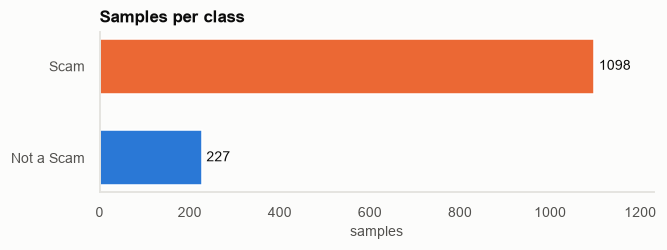

,turns,scam_class,scam_type,source,scam_start_turn,call_id,scam_outcome,scam_outcome_source
0,"[(caller, สวัสดีครับ ติดต่อจาก กรมสรรพากร ครับ เรียนคุณ ปุณณ์ ครับ ไม่ต้องตกใจครับ ทางเราโทรมาเพื่อแจ้งข่าวดีเกี่ยวกับเงินคืนภาษีของท่านครับ), (receiver, สวัสดีครับ ภาษีคืนเหรอครับ แล้วมียอดเท่าไห...",Scam,fake_authority,simulated,0.0,fake_authority_00050,safe,inferred
1,"[(caller, สวัสดีค่ะ ทางเราติดต่อมาจาก การไฟฟ้านครหลวง นะคะ ขออนุญาตสอบถามว่า เป็นคุณ ภูมิพัฒน์ ใช่ไหมคะ), (receiver, ใช่ครับ ผมเอง มีธุระอะไรหรือครับ), (caller, ไม่ตองตกใจนะคะ ทางเราโทรมาแจ้งว่าต้...",Scam,fake_authority,simulated,2.0,fake_authority_00051,safe,inferred
2,"[(caller, สวัสดีค่ะ ติดต่อจาก กระทรวงการคลัง นะคะ เรียกสายคุณ ภูริ ค่ะ), (receiver, สวัสดีครับ ผมเอง มีธุระอะไรหรือครับ), (caller, คือทางเราโทรมาแจ้งว่าคุณ ภูริ มีสิทธิ์ได้รับเงินอุดหนุนจากรัฐบาลน...",Scam,fake_authority,simulated,4.0,fake_authority_00052,safe,inferred


In [40]:
DATA_FILES = sorted(DATA_DIR.glob(DATA_PATTERN))
if not DATA_FILES:
    raise FileNotFoundError(f"no {DATA_PATTERN} file in {DATA_DIR}")
loaded, rejected = {}, {}
for path in DATA_FILES:
    loaded[path.name], rejected[path.name] = load_jsonl(path)
print(
    pd.DataFrame(
        {
            "calls": {n: len(f) + rejected[n] for n, f in loaded.items()},
            "rejected (dropped)": rejected,
            "kept": {n: len(f) for n, f in loaded.items()},
        }
    ).to_string()
)
raw = pd.concat(loaded.values(), ignore_index=True)

twice = raw["call_id"].duplicated(keep=False)
if twice.any():
    raise ValueError(f"call ids in more than one row: {sorted(set(raw.loc[twice, 'call_id']))[:5]}")

raw["scam_type"] = raw["scam_type"].fillna("").astype(str).str.strip()
raw["scam_start_turn"] = pd.to_numeric(raw["scam_start_turn"], errors="coerce")

print(raw.shape)
print(
    pd.crosstab(raw["scam_type"].replace("", "normal"), raw["scam_outcome"].fillna("none"))
    .rename_axis(index="type", columns="scam_outcome")
    .to_string()
)
class_counts = raw["scam_class"].value_counts()

fig, ax = plt.subplots(figsize=(6.5, 1.9))
ax.barh(
    class_counts.index,
    class_counts.to_numpy(),
    height=0.6,
    color=[CLASS_COLORS.get(c, NEUTRAL) for c in class_counts.index],
)
label_bars(ax)
ax.invert_yaxis()
ax.set(title="Samples per class", xlabel="samples", xlim=(0, class_counts.max() * 1.12))
plt.show()

raw.head(3)

## Step 2. Exploratory data analysis (EDA): data leakage

Data leakage means the input holds a clue to the label that will not exist at inference time.
A classifier uses any such shortcut.

The first chart counts what should never be in a generated call. Step 3 removes or drops it:

- notes that are not speech, such as `[วางสาย]` or `(เสียงร้องไห้)`
- a word that names a label (`LABEL_WORDS`), such as "scam" or "ฟิชชิ่ง"

The table after it counts `SHORTCUT_WORDS`: words people really say, in scam calls and in
normal calls. A word that shows up in one class only is a shortcut the model can learn instead
of the scam. Those calls stay. The fix is more data: normal calls that say the word too.

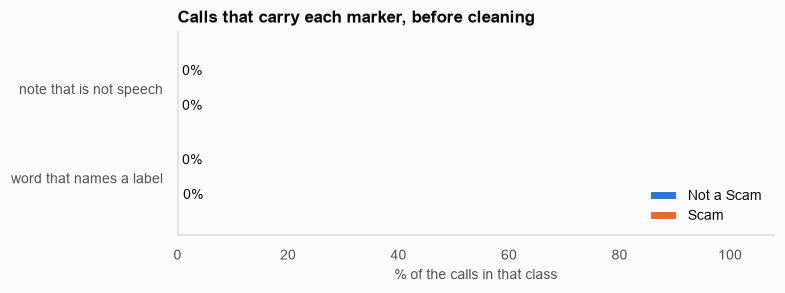

scam_class               Not a Scam  Scam
note that is not speech           0     0
word that names a label           0     2


,% of Not a Scam calls,% of Scam calls
มิจฉาชีพ,0.0,18.1
แอบอ้าง,0.0,2.0
หลอกลวง,0.0,0.4
ต้มตุ๋น,0.0,0.0
แก๊ง,0.0,0.0
คอลเซ็นเตอร์,1.8,0.2
OTP,4.4,7.2


In [41]:
spoken = raw["turns"].map(call_text)
checks = pd.DataFrame(
    {
        "note that is not speech": spoken.str.contains(BRACKET_NOTE)
        | spoken.str.contains(STAGE_NOTE),
        "word that names a label": spoken.str.contains(LABEL_WORDS),
    }
)
by_class = checks.groupby(raw["scam_class"])
share = (by_class.mean() * 100).T

ax = share.plot.barh(
    figsize=(7, 2.4), width=0.78, edgecolor=SURFACE, linewidth=2,
    color=[CLASS_COLORS.get(c, NEUTRAL) for c in share.columns],
)  # fmt: skip
label_bars(ax, "{:.0f}%")
ax.invert_yaxis()
ax.set(
    title="Calls that carry each marker, before cleaning",
    xlabel="% of the calls in that class",
    xlim=(0, 108),
)
ax.legend(title=None, loc="lower right")
plt.show()
print(by_class.sum().T.to_string())

shortcuts = (
    pd.DataFrame({word: spoken.str.contains(word, regex=False) for word in SHORTCUT_WORDS})
    .groupby(raw["scam_class"])
    .mean()
    .T.mul(100)
    .round(1)
)
shortcuts.columns = [f"% of {c} calls" for c in shortcuts.columns]
shortcuts.style.background_gradient(cmap=BLUES, axis=None).format("{:.1f}")

## Step 3. Data cleaning and text preprocessing

For each call:

1. Take its turns from the JSONL file: speaker A is the caller, B the receiver.
2. Remove bracket notes and stage notes such as `(เสียงร้องไห้)`, if a call has any.
3. Normalize the text with `pythainlp.util.normalize`: it removes zero-width characters and
   repeated or misplaced vowels and tone marks, which look the same on screen but are
   different strings to a model. Then keep one space between words.
4. Drop turns that are now empty and join consecutive turns from the same speaker.
5. Write the dialogue as `A: ...` / `B: ...`, one turn per line.

The last step matches what the classifier sees in the app. `CallState._render` in
`tts_voice_agent/memory.py` builds the text as `"{speaker}: {text}"` joined by newlines, and
the diarizer names speakers A, B in the order they first speak.

In [42]:
# The web system calls this same function, so training and serving see the same text.
from nlp_core.text import normalize_text


def clean_turns_mapped(raw_turns: list[tuple[str, str]]) -> tuple[list[tuple[str, str]], list[int]]:
    """Return ([(role, text), ...], where). Notes are removed, the text is normalized, and
    where[i] is the index in the cleaned turns of the i-th turn as written."""
    turns: list[tuple[str, str]] = []
    where: list[int] = []
    for role, text in raw_turns:
        text = normalize_text(STAGE_NOTE.sub(" ", BRACKET_NOTE.sub(" ", text)))
        if not text:
            where.append(len(turns))  # an emptied turn: the next kept turn takes its place
            continue
        if turns and turns[-1][0] == role:
            turns[-1] = (role, f"{turns[-1][1]} {text}")
        else:
            turns.append((role, text))
        where.append(len(turns) - 1)
    return turns, where


def clean_turns(raw_turns: list[tuple[str, str]]) -> list[tuple[str, str]]:
    return clean_turns_mapped(raw_turns)[0]


def clean_start(start, where: list[int]):
    """scam_start_turn counted in the cleaned turns, or None when it is not known."""
    if pd.isna(start) or not 0 <= int(start) < len(where):
        return None
    return where[int(start)]


def speaker_turns(turns: list[tuple[str, str]]) -> list[dict]:
    """Name speakers A, B by who speaks first, like the diarizer does."""
    letters: dict[str, str] = {}
    out = []
    for role, text in turns:
        if role not in letters:
            letters[role] = "AB"[len(letters)]
        out.append(
            {"speaker": letters[role], "role": role, "start": None, "end": None, "text": text}
        )
    return out


def render(turns: list[dict]) -> str:
    return "\n".join(f"{t['speaker']}: {t['text']}" for t in turns)


df = raw.copy()
cleaned = df["turns"].map(clean_turns_mapped)
df["speaker_turns"] = cleaned.map(lambda c: speaker_turns(c[0]))
df["scam_start_clean"] = pd.Series(
    [clean_start(s, c[1]) for s, c in zip(df["scam_start_turn"], cleaned, strict=True)],
    index=df.index,
    dtype="Int64",
)
df["text"] = df["speaker_turns"].map(render)

print(f"{df['call_id'].iat[0]} as the model sees it:\n" + df["text"].iat[0])

fake_authority_00050 as the model sees it:
A: สวัสดีครับ ติดต่อจาก กรมสรรพากร ครับ เรียนคุณ ปุณณ์ ครับ ไม่ต้องตกใจครับ ทางเราโทรมาเพื่อแจ้งข่าวดีเกี่ยวกับเงินคืนภาษีของท่านครับ
B: สวัสดีครับ ภาษีคืนเหรอครับ แล้วมียอดเท่าไหร่หรือมีเรื่องอะไรเพิ่มเติมไหมครับ
A: ยอดเงินคืนของท่านอยู่ที่ประมาณ 85,000 บาทครับ ทางเราขอแจ้งว่าเงินคืนนี้จะหมดเขตภายในวันนี้เท่านั้นครับ ซึ่งท่านสามารถดำเนินการได้ผ่านระบบออนไลน์อย่างปลอดภัยครับ
B: เอ่อ... ขอทราบชื่อผู้แจ้งหรือเลขที่อ้างอิงหน่อยครับ แล้วทำไมถึงต้องรีบทำวันนี้เท่านั้นครับ
A: ผมชื่อ ธนดล จากแผนกบริหารภาษีครับ สำหรับเรื่องนี้ทางเราต้องดำเนินการตามขั้นตอนความปลอดภัยสูงสุดครับ ซึ่งต้องใช้เวลาไม่นาน แต่ต้องทำภายในวันนี้เท่านั้นครับ
B: อ๋อ... ผมขอเช็คเองในระบบก่อนนะครับ ไม่สะดวกคุยต่อแล้ว


Check that the cleaning worked. A call that fails a check is dropped and its id printed, so one
odd call in a new file does not stop the notebook. A call that names a label (`LABEL_WORDS`)
is dropped here.

In [43]:
after = pd.DataFrame(
    {
        "bracket left": df["text"].str.contains(r"[\[\]]"),
        "word that names a label": df["text"].str.contains(LABEL_WORDS),
        "fewer than 2 turns": df["speaker_turns"].map(len) < 2,
    }
)
print(after.sum().to_string())

failed = after.any(axis=1)
if failed.any():
    print(f"\ndropped {failed.sum()} calls that failed a check:")
    print(df.loc[failed, ["call_id", "text"]].assign(text=df["text"].str.slice(0, 100)).to_string())
df = df[~failed].reset_index(drop=True)
assert len(df), "no call passed the cleaning checks"

print(f"\n{len(df)} samples left")

bracket left               0
word that names a label    2
fewer than 2 turns         0

dropped 2 calls that failed a check:
                   call_id                                                                                                   text
2     fake_authority_00052  A: สวัสดีค่ะ ติดต่อจาก กระทรวงการคลัง นะคะ เรียกสายคุณ ภูริ ค่ะ\nB: สวัสดีครับ ผมเอง มีธุระอะไรหรือคร
1289         romance_00243  A: ฮัลโหลตัวเอง ทำอะไรอยู่ครับ เหนื่อยไหมวันนี้\nB: ฮัลโหลคับตัวเอง เค้าเพิ่งเคลียร์งานเสร็จเนี่ย เหน

1323 samples left


Length is one more thing that differs between the classes. The chart shows the number of
characters per dialogue after cleaning, and the table gives the median for each class.
Cleaning does not change this, so read the scores with it in mind.

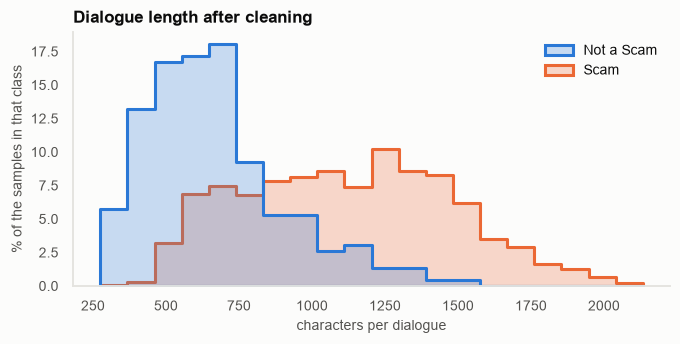

,median characters
scam_class,
Not a Scam,636.0
Scam,1124.0


In [44]:
df["characters"] = df["text"].str.len()

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(
    data=df, x="characters", hue="scam_class", hue_order=list(CLASS_COLORS), palette=CLASS_COLORS,
    bins=20, stat="percent", common_norm=False, element="step", alpha=0.25, linewidth=2, ax=ax,
)  # fmt: skip
ax.set(
    title="Dialogue length after cleaning",
    xlabel="characters per dialogue",
    ylabel="% of the samples in that class",
)
ax.get_legend().set_title(None)
plt.show()

df.groupby("scam_class")["characters"].median().rename("median characters").to_frame()

## Step 4. Label mapping (target variables)

The spec has a gate (`label_scam`) and 5 types (`label_type`). The simulated calls already use
the 5 spec names, which `TYPE_MAP` maps to themselves. The other names in the map come from the
hand-written spreadsheet and assign each of its type names to a spec type. `None` means "a scam, but none of the
5 types": the sample still trains the gate, and the type model skips it.

The mapping is a judgment call, so edit it if the team disagrees. A scam type name that is
not in the map is printed below and treated as `None`.

Exact duplicates are removed here, after the mapping. Two dialogues that differed only in a
hang-up note or a narration line are the same text after cleaning. If the copies agree on the
label, one is kept. If they disagree, the text does not decide the label, so every copy is
dropped and printed.

dropped 0 exact duplicates with the same label, 1323 samples left


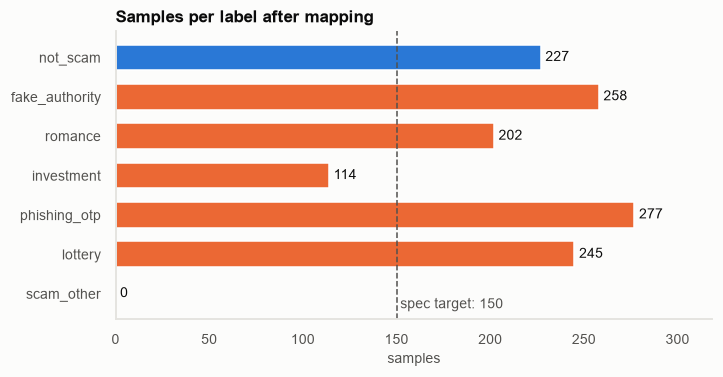

,samples,spec target,short by
stratum,,,
not_scam,227,150,0
fake_authority,258,150,0
romance,202,150,0
investment,114,150,36
phishing_otp,277,150,0
lottery,245,150,0
scam_other,0,0,150


In [45]:
TYPE_MAP: dict[str, str | None] = {
    # the 5 spec types by their own names: what data_pipeline writes for simulated calls
    "fake_authority": "fake_authority",
    "romance": "romance",
    "investment": "investment",
    "phishing_otp": "phishing_otp",
    "lottery": "lottery",
    # fake authority / call center: the caller claims to be an official or a company agent
    "Police Impersonation": "fake_authority",
    "Government Official Impersonation": "fake_authority",
    "Military Impersonation": "fake_authority",
    "Utility Impersonation": "fake_authority",
    "Bank Impersonation": "fake_authority",
    "Telecom Impersonation": "fake_authority",
    "Social Security Impersonation": "fake_authority",
    "Delivery Service Impersonation": "fake_authority",
    "Customs/Delivery Scam": "fake_authority",
    "Traffic Ticket Scam": "fake_authority",
    "Debt Collection Scam": "fake_authority",
    "Tax Deduction Scam": "fake_authority",
    "Tax Refund Scam": "fake_authority",
    "ATM Tax Refund Scam": "fake_authority",
    "Government Grant Scam": "fake_authority",
    "Government Compensation Scam": "fake_authority",
    "Grant/Subsidy Scam": "fake_authority",
    "Pension Scam": "fake_authority",
    "Student Loan Scam": "fake_authority",
    "Scholarship Scam": "fake_authority",
    "Insurance Claim Scam": "fake_authority",
    "Medical Insurance Scam": "fake_authority",
    # phishing / OTP: the goal is a code, a card number, a link, a QR scan or an app install
    "Bank OTP Phishing": "phishing_otp",
    "Fake Order Phishing": "phishing_otp",
    "Fake Delivery Phishing": "phishing_otp",
    "E-commerce Phishing": "phishing_otp",
    "Fake Flight Booking Scam": "phishing_otp",
    "Fake Hotel Booking Scam": "phishing_otp",
    "Tech Support Scam": "phishing_otp",
    "QR Code Scam": "phishing_otp",
    "Malware Download Scam": "phishing_otp",
    # investment
    "Investment Scam": "investment",
    "Dividend Scam": "investment",
    # lottery / prize
    "Lottery/Prize Scam": "lottery",
    "Prize/Lottery Scam": "lottery",
    # romance
    "Romance Scam": "romance",
    # scams outside the 5 spec types
    "Charity Scam": None,
    "Loan Approval Scam": None,
    "Overpayment Scam": None,
    "Family Emergency Scam": None,
    "Kidnapping/Family Emergency Scam": None,
    "Lost Item Scam": None,
}
assert set(filter(None, TYPE_MAP.values())) <= set(SCAM_TYPES)

df["label_scam"] = df["scam_class"].str.lower().map(SCAM_CLASS_VALUES).astype(bool)

unmapped = sorted(set(df.loc[df["label_scam"], "scam_type"]) - set(TYPE_MAP))
if unmapped:
    print("scam types missing from TYPE_MAP (treated as no type):", unmapped)

df["label_type"] = [
    TYPE_MAP.get(t) if is_scam else None
    for t, is_scam in zip(df["scam_type"], df["label_scam"], strict=True)
]
# The split is stratified on this column.
df["stratum"] = np.where(df["label_scam"], df["label_type"].fillna("scam_other"), "not_scam")

conflicting = df.groupby("text")["stratum"].transform("nunique") > 1
if conflicting.any():
    print(f"\ndropped {conflicting.sum()} samples: same text, different labels")
    print(
        df[conflicting]
        .groupby("text")["scam_type"]
        .agg(lambda s: " | ".join(sorted(set(s))))
        .to_string(index=False)
    )
before = len(df)
df = df[~conflicting].drop_duplicates(subset="text").reset_index(drop=True)
print(
    f"dropped {before - conflicting.sum() - len(df)} exact duplicates with the same label, {len(df)} samples left"
)

counts = df["stratum"].value_counts().rename("samples").to_frame()
counts["spec target"] = 150
counts.loc["scam_other", "spec target"] = 0
counts["short by"] = (counts["spec target"] - counts["samples"]).clip(lower=0)
counts = (
    counts.reindex(["not_scam", *SCAM_TYPES, "scam_other"])
    .fillna({"samples": 0, "spec target": 150, "short by": 150})
    .astype(int)
)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(
    counts.index, counts["samples"], height=0.65,
    color=[CLASS_COLORS["Not a Scam" if s == "not_scam" else "Scam"] for s in counts.index],
)  # fmt: skip
label_bars(ax)
ax.axvline(150, color=MUTED, linestyle="--", linewidth=1)
ax.text(152, len(counts) - 0.55, "spec target: 150", color=MUTED, fontsize=9, va="bottom")
ax.invert_yaxis()
ax.set(
    title="Samples per label after mapping",
    xlabel="samples",
    xlim=(0, max(counts["samples"].max(), 150) * 1.15),
)
plt.show()

counts.style.bar(subset=["short by"], color="#f5c2ad", vmin=0, vmax=150)

## Step 4b. Balancing

Every scam type gets the same number of calls, and within a type the numbers of `scammed` and
`safe` calls are equal. Normal calls get the same number as one scam type.

1. The first table counts the usable calls (after cleaning and deduplication) of each scam
   type and outcome. Calls whose outcome was never set (`none`) cannot be balanced and are
   left out.
2. The common size is the smaller of `TARGET_PER_TYPE // 2` and the smallest scammed or safe
   count of any type. The cell prints which type set it.
3. A type listed in `SKIP_TYPES` is left out completely, for example one whose file has only a
   few calls and would otherwise shrink every other type.
4. Calls are picked with the seed: `locked` outcomes first, then `inferred`, at random within
   each.

The second table shows what is kept. `stratum` (type and outcome) is what step 6 stratifies on.

In [46]:
TARGET_PER_TYPE = 167  # calls per scam type to aim for, half scammed and half safe
SKIP_TYPES: set[str] = set()  # scam types left out, e.g. {"romance"} while it has few calls
OUTCOMES = ("scammed", "safe")
# Which calls are picked first: a lower number first, at random within one number.
OUTCOME_SOURCE_ORDER = {"locked": 0, "inferred": 1}


def pick(frame: pd.DataFrame, n: int, rng: np.random.Generator) -> list:
    """The index of n rows of frame: locked outcomes first, then inferred, at random within each."""
    order = frame["scam_outcome_source"].map(OUTCOME_SOURCE_ORDER).fillna(len(OUTCOME_SOURCE_ORDER))
    ranked = pd.DataFrame({"order": order, "draw": rng.random(len(frame))}, index=frame.index)
    return list(ranked.sort_values(["order", "draw"]).index[:n])


typed_scam = df["label_scam"] & df["label_type"].notna()
outcome = df["scam_outcome"].where(df["scam_outcome"].isin(OUTCOMES), "none")
available = pd.crosstab(df.loc[typed_scam, "label_type"], outcome[typed_scam]).reindex(
    columns=[*OUTCOMES, "none"], fill_value=0
)
available["skipped"] = available.index.isin(SKIP_TYPES)
print("usable calls per scam type and outcome:")
print(available.to_string())

kept_types = [t for t in available.index if t not in SKIP_TYPES]
if not kept_types:
    raise ValueError("no scam type is left to balance: add calls or empty SKIP_TYPES")
counts = available.loc[kept_types, list(OUTCOMES)]
smallest = counts.stack().idxmin()  # (type, outcome) with the fewest calls
PER_OUTCOME = int(min(TARGET_PER_TYPE // 2, counts.to_numpy().min()))
if PER_OUTCOME == 0:
    raise ValueError(
        f"{smallest[0]} has no {smallest[1]} calls. Add it to SKIP_TYPES or add {smallest[1]} calls."
    )
print(
    f"\n{PER_OUTCOME} scammed + {PER_OUTCOME} safe calls per scam type, {2 * PER_OUTCOME} in all. "
    f"Smallest group: {smallest[0]} / {smallest[1]} with {counts.loc[smallest]} calls."
)

rng = np.random.default_rng(SEED)
keep: list = []
for label_type in kept_types:
    for name in OUTCOMES:
        keep += pick(
            df[typed_scam & (df["label_type"] == label_type) & (outcome == name)], PER_OUTCOME, rng
        )
normal = df[~df["label_scam"]]
if len(normal) < 2 * PER_OUTCOME:
    print(f"only {len(normal)} normal calls, fewer than the {2 * PER_OUTCOME} of one scam type")
keep += pick(normal, 2 * PER_OUTCOME, rng)
untyped = int((df["label_scam"] & df["label_type"].isna()).sum())
if untyped:
    print(f"left out {untyped} scam calls with no spec type")

df = df.loc[sorted(keep)].reset_index(drop=True)
# Step 6 stratifies on this, so each split keeps the balance of types and outcomes.
df["stratum"] = np.where(
    df["label_scam"],
    df["label_type"].fillna("") + "/" + df["scam_outcome"].fillna(""),
    "not_scam",
)
print(f"\n{len(df)} samples kept")
pd.crosstab(df["label_type"].fillna("normal"), df["scam_outcome"].fillna("-")).rename_axis(
    index="type", columns="scam_outcome"
)

usable calls per scam type and outcome:
scam_outcome    scammed  safe  none  skipped
label_type                                  
fake_authority      108   150     0    False
investment           48    66     0    False
lottery             119   126     0    False
phishing_otp        128   149     0    False
romance             102   100     0    False

48 scammed + 48 safe calls per scam type, 96 in all. Smallest group: investment / scammed with 48 calls.

576 samples kept


scam_outcome,-,safe,scammed
type,,,
fake_authority,0,48,48
investment,0,48,48
lottery,0,48,48
normal,96,0,0
phishing_otp,0,48,48
romance,0,48,48


## Step 5. Near-duplicate detection

Many samples come from the same template with a few words changed. If one copy lands in train and
another in test, the test score measures memory of the template. This step puts samples that are
almost the same into one group, and step 6 keeps each group inside one split.

Similarity is the cosine between TF-IDF vectors of character n-grams. Samples are linked when
the similarity is at least `NEAR_DUPLICATE_SIMILARITY`, and a group is a set of linked samples.

Only the text decides. Two paraphrases of one scenario that score below the threshold can end
up in different splits, so lower `NEAR_DUPLICATE_SIMILARITY` if the test score looks too good.

The histogram shows, for each sample, how similar its closest other sample is. Samples to the right
of the dashed line have a near copy somewhere in the file.

576 samples in 575 groups
1 groups hold more than one sample (2 samples), largest has 2


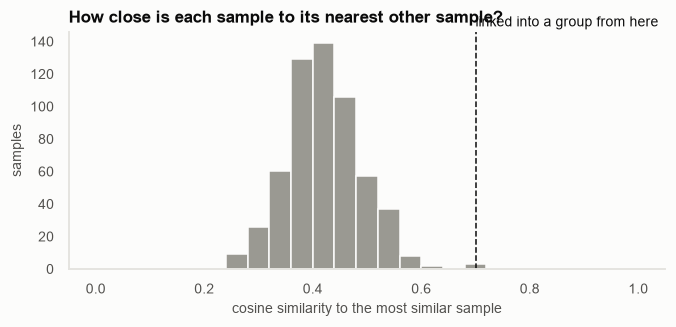


most similar pair (0.70):
A: สวัสดีค่ะ คุณพิชชาภา ใช่ไหมคะ ดิฉันโทรจากทรัพย์ทวี แคปปิตอล นะคะ จะแจ้งว่าประกันรถยนต์ของคุณกำลังจะหมดอายุสัปดาห์หน้าแล้วค่ะ
B: ใช่ค่ะ หมดอายุแล้วเหรอคะ ต้องทำยังไงบ้างคะ
A: คุณพิชชาภาสามารถต่ออายุผ่านแอปพลิเคชันได้เลย หรือจะเข้าไปทำที่สาขาใกล้บ้านก็ได้ค่ะ ให้เราส่งรายละเอียดการต่ออายุไปให้ทางข้อความไหมคะ
B: ส่งมาทางข้อความได้เลยค่ะ ขอบคุณค่ะ
A: ได้เลยค่ะ เดี๋ยวเราส่งรายละเอียดให้ทางข้อความนะคะ ขอบคุณที่ใช้บริการค่ะ สวัสดีค่ะ 
---
A: สวัสดีครับคุณ ปภังกร ผมโทรจาก ทรัพย์ทวี แคปปิตอล นะครับ จะแจ้งว่าประกันรถยนต์ของคุณกำลังจะหมดอายุสัปดาห์หน้าครับ
B: สวัสดีครับ อ๋อ ครับผม จะหมดอายุแล้วเหรอครับ แล้วต้องทำยังไงบ้างครับ
A: คุณ ปภังกร สามารถต่ออายุผ่านแอปพลิเคชันได้เลย หรือจะเข้าไปที่สาขาใกล้บ้านก็ได้ครับ ให้ผมส่งรายละเอียดการต่ออายุไปให้ทางข้อความไหมครับ
B: ได้ครับ ส่งรายละเอียดมาทางข้อความได้เลยครับ ผมจะได้เช็คดูว่ามีแบบไหนที่คุ้มค่าบ้าง
A: ได้ครับ เดี๋ยวผมรีบส่งรายละเอียดให้ทางข้อความเลยครับ ขอบคุณมากครับ สวัสดีครับ


In [47]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer

body = df["text"].str.replace(r"(?m)^[AB]: ", "", regex=True)
vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True).fit_transform(
    body
)
similarity = (vectors @ vectors.T).toarray()
np.fill_diagonal(similarity, 0.0)

linked = similarity >= NEAR_DUPLICATE_SIMILARITY
n_groups, df["group"] = connected_components(csr_matrix(linked), directed=False)
sizes = df["group"].value_counts()
print(f"{len(df)} samples in {n_groups} groups")
print(
    f"{(sizes > 1).sum()} groups hold more than one sample ({sizes[sizes > 1].sum()} samples), largest has {sizes.max()}"
)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(
    similarity.max(axis=1), bins=25, range=(0, 1), color=NEUTRAL, edgecolor=SURFACE, linewidth=1
)
ax.axvline(NEAR_DUPLICATE_SIMILARITY, color=INK, linestyle="--", linewidth=1)
ax.text(
    NEAR_DUPLICATE_SIMILARITY,
    1.01,
    "linked into a group from here",
    transform=ax.get_xaxis_transform(),
    color=INK,
    fontsize=9,
    va="bottom",
)
ax.set(
    title="How close is each sample to its nearest other sample?",
    xlabel="cosine similarity to the most similar sample",
    ylabel="samples",
)
plt.show()

a, b = np.unravel_index(similarity.argmax(), similarity.shape)
print(f"\nmost similar pair ({similarity[a, b]:.2f}):")
print(df.loc[a, "text"], "\n---\n" + df.loc[b, "text"])

## Step 6. Train / validation / test split (70 / 15 / 15)

The spec asks for a fixed split with seed 42, stratified by `label_type`. This version
stratifies by type and outcome (the `stratum` from step 4b), so train, valid and test each keep
the balance, and it keeps every near-duplicate group in one split. Because a group cannot be
cut, the counts per split are close to 70 / 15 / 15, not exact.

Every run splits the calls again from scratch. No saved split is read, so nothing from an
older run (and nothing from the hand-written `data/processed/`) ends up in the new test set.

Groups are shuffled with the seed and handled largest first. Each group goes to the split
that is furthest below its target sample count for that group's label.

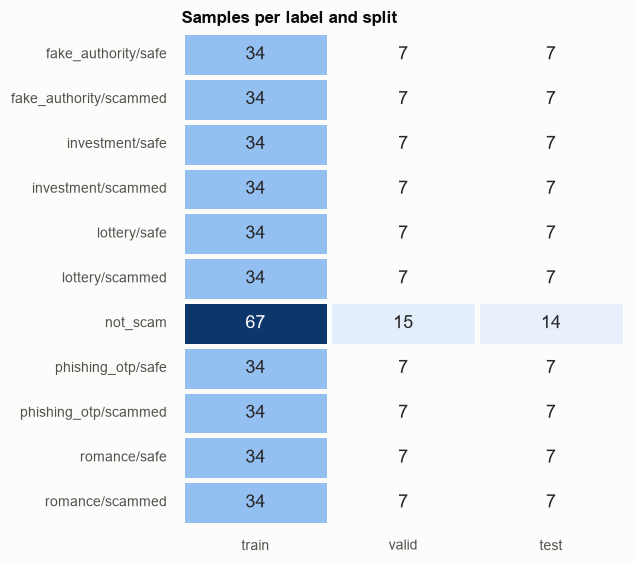

split,train,valid,test
stratum,,,
fake_authority/safe,34,7,7
fake_authority/scammed,34,7,7
investment/safe,34,7,7
investment/scammed,34,7,7
lottery/safe,34,7,7
lottery/scammed,34,7,7
not_scam,67,15,14
phishing_otp/safe,34,7,7
phishing_otp/scammed,34,7,7


In [48]:
def group_stratified_split(frame: pd.DataFrame, ratios: dict[str, float], seed: int) -> pd.Series:
    groups = (
        frame.groupby("group")
        .agg(stratum=("stratum", lambda s: s.mode().iat[0]), n=("stratum", "size"))
        .sample(frac=1.0, random_state=seed)
        .sort_values("n", ascending=False, kind="stable")
    )
    totals = groups.groupby("stratum")["n"].sum()
    filled: dict[str, Counter] = defaultdict(Counter)
    assigned: dict[int, str] = {}
    for g in groups.itertuples():
        gaps = {
            name: ratio * totals[g.stratum] - filled[g.stratum][name]
            for name, ratio in ratios.items()
        }
        split = max(gaps, key=gaps.get)
        assigned[g.Index] = split
        filled[g.stratum][split] += g.n
    return frame["group"].map(assigned)


df["split"] = group_stratified_split(df, SPLIT_RATIOS, SEED)
cut = df.groupby("group")["split"].nunique()
assert cut.max() == 1, "a group was cut across splits"

table = pd.crosstab(df["stratum"], df["split"]).reindex(columns=list(SPLIT_RATIOS), fill_value=0)

fig, ax = plt.subplots(figsize=(5.2, 0.42 * len(table) + 1.2))
table_heatmap(table, ax, "d")
ax.set(title="Samples per label and split", xlabel="", ylabel="")
plt.show()

table.loc["total"] = table.sum()
table

## Step 7. Export the processed dataset

One sample per row, with the fields of the record schema in `docs/spec.html` as columns,
written to `data/processed_balanced/{train,valid,test,dataset}.csv`.
A csv cell cannot hold a list, so `speaker_turns` and `entities` are written as JSON text
and parsed again when part B reads the file. Fields this dataset cannot fill
(`audio_path`, `entities`, `reference_summary`) are empty. `scam_start_turn` is counted in the
cleaned turns.

Extra columns, not part of the spec schema:

- `source`: `simulated`.
- `raw_type`: the type as the file wrote it, so the mapping can be changed later.
- `group`: the near-duplicate group from step 5. Cross-validation in step 12 needs it to keep
  near copies in the same fold.
- `call_id`: the call's id in its JSONL file.
- `scam_outcome` and `scam_outcome_source`: `scammed` or `safe`, and `locked` or `inferred`.
  Empty for normal calls. No model reads them; they let the scores be split by outcome.

Every record passes a schema check before the files are written.

In [49]:
RECORD_KEYS = (
    "id", "channel", "text", "audio_path", "speaker_turns", "label_scam", "label_type",
    "entities", "reference_summary", "scam_start_turn", "source", "raw_type", "group",
    "call_id", "scam_outcome", "scam_outcome_source",
)  # fmt: skip


def text_or_none(value):
    """A csv cell from an optional text column: None when it is empty or NaN."""
    return value if isinstance(value, str) and value else None


def to_record(sample) -> dict:
    return {
        "id": f"call_{sample.Index + 1:05d}",
        "channel": "call",
        "text": sample.text,
        "audio_path": None,
        "speaker_turns": sample.speaker_turns,
        "label_scam": bool(sample.label_scam),
        "label_type": sample.label_type,
        "entities": [],
        "reference_summary": None,
        "scam_start_turn": None
        if pd.isna(sample.scam_start_clean)
        else int(sample.scam_start_clean),
        "source": sample.source,
        "raw_type": sample.scam_type,
        "group": int(sample.group),
        "call_id": sample.call_id,
        "scam_outcome": text_or_none(sample.scam_outcome),
        "scam_outcome_source": text_or_none(sample.scam_outcome_source),
    }


def check_record(rec: dict) -> None:
    assert tuple(rec) == RECORD_KEYS, f"{rec.get('id')}: wrong keys"
    assert rec["channel"] in ("call", "message")
    assert rec["text"].strip(), f"{rec['id']}: empty text"
    assert isinstance(rec["label_scam"], bool)
    assert rec["label_type"] is None or rec["label_type"] in SCAM_TYPES, (
        f"{rec['id']}: bad label_type"
    )
    assert rec["label_scam"] or rec["label_type"] is None, f"{rec['id']}: type on a normal call"
    assert rec["label_scam"] or rec["scam_outcome"] is None, (
        f"{rec['id']}: outcome on a normal call"
    )
    assert all(t["speaker"] and t["text"] for t in rec["speaker_turns"])


LIST_COLUMNS = ("speaker_turns", "entities")  # stored as JSON text inside the csv


def write_records(path: Path, records: list[dict]) -> None:
    frame = pd.DataFrame(records, columns=list(RECORD_KEYS))
    frame["scam_start_turn"] = frame["scam_start_turn"].astype("Int64")
    for col in LIST_COLUMNS:
        frame[col] = frame[col].map(lambda value: json.dumps(value, ensure_ascii=False))
    frame.to_csv(path, index=False, encoding=CSV_ENCODING)


split_files = {name: PROCESSED / f"{name}.csv" for name in SPLIT_RATIOS}

if REBUILD_SPLIT or not all(p.exists() for p in split_files.values()):
    df["label_type"] = df["label_type"].astype(object).where(df["label_type"].notna(), None)
    records = {name: [] for name in SPLIT_RATIOS}
    for sample in df.itertuples():
        rec = to_record(sample)
        check_record(rec)
        records[sample.split].append(rec)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    write_records(PROCESSED / "dataset.csv", [r for name in SPLIT_RATIOS for r in records[name]])
    for name, path in split_files.items():
        write_records(path, records[name])
        print(f"wrote {len(records[name]):4d} records to {path.relative_to(ROOT)}")
else:
    print("kept the split on disk (REBUILD_SPLIT is False)")

wrote  407 records to data\processed_balanced\train.csv
wrote   85 records to data\processed_balanced\valid.csv
wrote   84 records to data\processed_balanced\test.csv


# Part B. Modeling and evaluation

From here on the notebook reads only `data/processed/{train,valid,test}.csv`.

- Gate labels: `not_scam`, `scam`. Trained on every sample.
- Type labels: the spec types that have at least `MIN_TYPE_SAMPLES` samples in total and at
  least `MIN_TYPE_EVAL_SAMPLES` in valid and in test. Trained on scam samples with one of those
  types. The other types are listed as not enough data and are not scored.
- `outside` holds the scam samples the type model never trains on: scams with no spec type
  and scams of a type without enough data. Step 13 uses them to check what the type model
  answers for a scam it does not know.

In [ ]:
def read_records(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, encoding=CSV_ENCODING)
    for col in LIST_COLUMNS:
        frame[col] = frame[col].map(json.loads)
    # An empty csv cell is read as NaN. Turn it back into None.
    return frame.astype(object).where(frame.notna(), None).astype({"label_scam": bool})


data = {name: read_records(PROCESSED / f"{name}.csv") for name in SPLIT_RATIOS}

GATE_LABELS = ["not_scam", "scam"]
for frame in data.values():
    frame["gate"] = frame["label_scam"].astype(int)

type_counts = (
    pd.DataFrame({name: frame["label_type"].value_counts() for name, frame in data.items()})
    .reindex(SCAM_TYPES)
    .fillna(0)
    .astype(int)
)
type_counts["total"] = type_counts.sum(axis=1)

enough = (
    (type_counts["total"] >= MIN_TYPE_SAMPLES)
    & (type_counts["train"] > 0)
    & (type_counts[["valid", "test"]] >= MIN_TYPE_EVAL_SAMPLES).all(axis=1)
)
TYPE_LABELS = [t for t in SCAM_TYPES if enough[t]]
NOT_ENOUGH_DATA = [t for t in SCAM_TYPES if not enough[t]]
TRAIN_TYPE_MODEL = len(TYPE_LABELS) >= 2

typed = {name: frame[frame["label_type"].isin(TYPE_LABELS)].copy() for name, frame in data.items()}
for frame in typed.values():
    frame["type"] = frame["label_type"].map(TYPE_LABELS.index)

# The type model sees none of these in training, whatever split they are in.
outside = pd.concat(
    [
        frame[frame["label_scam"] & ~frame["label_type"].isin(TYPE_LABELS)]
        for frame in data.values()
    ],
    ignore_index=True,
)
TYPE_MIN_CONFIDENCE = 0.50  # below this the type model's answer is dropped (steps 13 and 14)

print("type model trains on:", TYPE_LABELS)
print("not enough data:     ", NOT_ENOUGH_DATA)
print("scam samples outside the trained types:", len(outside))
type_counts.style.background_gradient(cmap=BLUES, axis=None)

## Step 8. Baseline model: TF-IDF features + logistic regression

A baseline is a simple model that the fine-tuned model has to beat. Its features are TF-IDF
weights. Thai has no spaces between words, so the text is first cut into words with
PyThaiNLP (`newmm`, a dictionary-based tokenizer), then counts words and word pairs.
`class_weight="balanced"` stops it from always answering with the biggest class.

`score` is the one scoring function in this notebook. Every model goes through it with the
test set, so the numbers are comparable. It also prints a 95% bootstrap interval for
macro-F1: the range the score would fall in if the test set were drawn again. A wide
interval means the test set is too small to trust the number. It draws two tables: the confusion matrix on the
left (true label down the side, predicted label across the top) and precision, recall and
F1 for each class on the right.

In [ ]:
from pythainlp.tokenize import word_tokenize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.pipeline import make_pipeline

results: list[dict] = []
N_BOOTSTRAP = 2000  # resamples of the test set for the confidence interval


def score(task: str, model: str, y_true, y_pred, label_names: list[str], sources=None) -> None:
    """Draw the confusion matrix and per-class P/R/F1, print the macro scores, keep the numbers."""
    ids = list(range(len(label_names)))
    p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=ids, zero_division=0)
    per_class = pd.DataFrame(
        {"precision": p, "recall": r, "f1": f1, "support": support}, index=label_names
    )
    macro = per_class[["precision", "recall", "f1"]].mean()
    # Bootstrap: draw the test set again with replacement many times and score each draw.
    # The middle 95% of those scores is the interval.
    truth, guess = np.asarray(y_true), np.asarray(y_pred)
    draws = np.random.default_rng(SEED).integers(0, len(truth), size=(N_BOOTSTRAP, len(truth)))
    resampled = [
        f1_score(truth[i], guess[i], labels=ids, average="macro", zero_division=0) for i in draws
    ]
    ci_low, ci_high = np.percentile(resampled, [2.5, 97.5])
    matrix = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=ids),
        index=[f"true {n}" for n in label_names],
        columns=[f"pred {n}" for n in label_names],
    )
    fig, (left, right) = plt.subplots(
        1, 2, figsize=(9.5, 0.5 * len(label_names) + 2.2), width_ratios=[1, 1.15]
    )
    wrapped = [name.replace("_", "\n") for name in label_names]
    table_heatmap(matrix.set_axis(label_names, axis=0).set_axis(wrapped, axis=1), left, "d")
    left.set(title="Confusion matrix (samples)", xlabel="predicted", ylabel="true")
    shown = per_class[["precision", "recall", "f1"]].set_axis(
        [f"{name} (n={n})" for name, n in zip(label_names, support, strict=True)]
    )
    table_heatmap(shown, right, ".2f", vmin=0, vmax=1)
    right.set_title("Scores per class")
    fig.suptitle(
        f"{task} / {model}, test set, n={len(y_true)}",
        x=0.01,
        ha="left",
        fontsize=11,
        fontweight="bold",
    )
    fig.tight_layout()
    plt.show()
    print(
        f"{task} / {model}: macro  P={macro['precision']:.3f}  R={macro['recall']:.3f}  F1={macro['f1']:.3f}"
        f"  (95% interval for F1: {ci_low:.2f} to {ci_high:.2f})"
    )
    by_source = {}
    if sources is not None and len(set(sources)) > 1:
        src = np.asarray(sources)
        for name in sorted(set(src)):
            m = src == name
            present = sorted(set(truth[m]) | set(guess[m]))
            by_source[name] = {
                "n": int(m.sum()),
                "macro_f1": round(
                    float(
                        f1_score(
                            truth[m], guess[m], labels=present, average="macro", zero_division=0
                        )
                    ),
                    4,
                ),
                "accuracy": round(float(accuracy_score(truth[m], guess[m])), 4),
            }
        print(pd.DataFrame(by_source).T.to_string())
    results.append(
        {
            "task": task,
            "model": model,
            "precision": round(float(macro["precision"]), 4),
            "recall": round(float(macro["recall"]), 4),
            "f1": round(float(macro["f1"]), 4),
            "f1_ci_low": round(float(ci_low), 4),
            "f1_ci_high": round(float(ci_high), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "n_test": int(len(y_true)),
            "per_class": per_class.round(4).to_dict(orient="index"),
            **({"by_source": by_source} if by_source else {}),
        }
    )


def thai_words(text: str) -> list[str]:
    return word_tokenize(text, engine="newmm", keep_whitespace=False)


def make_baseline():
    return make_pipeline(
        TfidfVectorizer(
            tokenizer=thai_words,
            token_pattern=None,
            lowercase=False,
            ngram_range=(1, 2),
            sublinear_tf=True,
            min_df=2,
        ),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    )


gate_baseline = make_baseline().fit(data["train"]["text"], data["train"]["gate"])
score(
    "scam_gate",
    "tfidf_logreg",
    data["test"]["gate"],
    gate_baseline.predict(data["test"]["text"]),
    GATE_LABELS,
    data["test"]["source"],
)

if TRAIN_TYPE_MODEL:
    type_baseline = make_baseline().fit(typed["train"]["text"], typed["train"]["type"])
    score(
        "scam_type",
        "tfidf_logreg",
        typed["test"]["type"],
        type_baseline.predict(typed["test"]["text"]),
        TYPE_LABELS,
        typed["test"]["source"],
    )

### Does the generated data help?

Only when generated rows are in train. The same baseline is trained twice, on the
hand-written train rows alone and on train with the generated rows, and both are scored on
the test set, as a whole and for each source. A fixed test set (`KEEP_ORIGINAL_TEST`) is
hand-written only, so it answers one question: do generated rows help on hand-written calls.
The fine-tuned model needs a second run with `GENERATED_FILE = None` for the same comparison.


In [ ]:
generated_in_train = (data["train"]["source"] != ORIGINAL_SOURCE).any()
if generated_in_train:
    rows = []
    train_sets = {
        "original only": data["train"]["source"] == ORIGINAL_SOURCE,
        "original + generated": data["train"]["source"].notna(),
    }
    for name, mask in train_sets.items():
        fit = data["train"][mask]
        pred = make_baseline().fit(fit["text"], fit["gate"]).predict(data["test"]["text"])
        for source in ["all", *sorted(set(data["test"]["source"]))]:
            pick = (data["test"]["source"] == source).to_numpy() if source != "all" else slice(None)
            y_true, y_pred = data["test"]["gate"].to_numpy()[pick], pred[pick]
            rows.append(
                {
                    "trained on": name,
                    "test rows": source,
                    "n": len(y_true),
                    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
                }
            )
    pd.DataFrame(rows).round(3)
else:
    print("no generated rows in train")

### Which speaker does the gate rely on?

The same baseline is trained three times: on the full dialogue, on the caller's turns only,
and on the receiver's turns only. It is scored on valid, so the test set stays untouched.

A scam call is defined by what the caller does. If the receiver's turns alone score as high
as the full dialogue, the gate can be solved from how the receiver reacts, and in this
dataset the receiver of a scam call almost always refuses. A model trained on that will be
weaker on calls where the victim goes along.

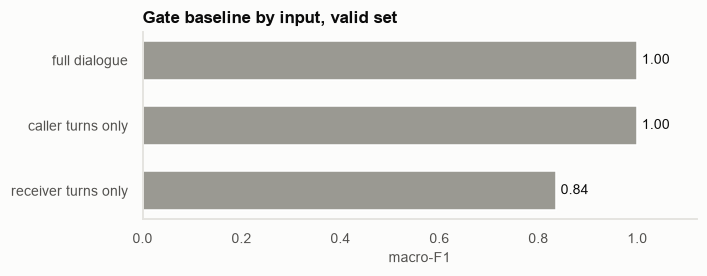

,valid macro-F1
full dialogue,1.000
caller turns only,1.000
receiver turns only,0.836


In [52]:
def turns_of(frame: pd.DataFrame, role: str) -> pd.Series:
    return frame["speaker_turns"].map(
        lambda turns: " ".join(t["text"] for t in turns if t["role"] == role)
    )


gate_inputs = {
    "full dialogue": lambda frame: frame["text"],
    "caller turns only": lambda frame: turns_of(frame, "caller"),
    "receiver turns only": lambda frame: turns_of(frame, "receiver"),
}
speaker_f1 = {}
for name, pick in gate_inputs.items():
    model = make_baseline().fit(pick(data["train"]), data["train"]["gate"])
    speaker_f1[name] = f1_score(
        data["valid"]["gate"], model.predict(pick(data["valid"])), average="macro"
    )
speaker_f1 = pd.Series(speaker_f1, name="valid macro-F1")

fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.barh(speaker_f1.index, speaker_f1.to_numpy(), height=0.6, color=NEUTRAL)
label_bars(ax, "{:.2f}")
ax.invert_yaxis()
ax.set(title="Gate baseline by input, valid set", xlabel="macro-F1", xlim=(0, 1.12))
plt.show()

speaker_f1.round(3).to_frame()

## Step 9. Tokenization

Two things to settle before training:

- Spaces. WangchanBERTa tokenizers need every space written as `<_>`. PhayaThaiBERT extends
  that vocabulary, so the cell checks whether `<_>` is a token and applies the rule only if it
  is. Newlines between turns become spaces first.
- Length. The token counts below show whether `MAX_LENGTH` cuts any dialogue.

In [ ]:
import torch
from transformers import AutoTokenizer

MODEL_ID = "clicknext/phayathaibert"
MAX_LENGTH = 256

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(
    "device:", torch.cuda.get_device_name(0) if device == "cuda" else "cpu (training will be slow)"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
SPACE_TOKEN = "<_>"
USE_SPACE_TOKEN = SPACE_TOKEN in tokenizer.get_vocab()


def to_model_text(text: str) -> str:
    text = " ".join(text.split())
    return text.replace(" ", SPACE_TOKEN) if USE_SPACE_TOKEN else text


lengths = pd.concat(data.values())["text"].map(
    lambda t: len(tokenizer(to_model_text(t))["input_ids"])
)
print("space token in use:", USE_SPACE_TOKEN)
print("tokens per dialogue:", lengths.describe().round(0).astype(int).to_dict())
print(f"dialogues longer than {MAX_LENGTH} tokens: {(lengths > MAX_LENGTH).sum()}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(lengths, bins=25, color=NEUTRAL, edgecolor=SURFACE, linewidth=1)
ax.axvline(MAX_LENGTH, color=INK, linestyle="--", linewidth=1)
ax.text(
    MAX_LENGTH,
    1.01,
    f"MAX_LENGTH = {MAX_LENGTH}",
    transform=ax.get_xaxis_transform(),
    color=INK,
    fontsize=9,
    va="bottom",
    ha="right",
)
ax.set(title="Tokens per dialogue", xlabel="PhayaThaiBERT tokens", ylabel="dialogues")
plt.show()

sample = to_model_text(data["train"]["text"].iat[0])[:60]
print(tokenizer.tokenize(sample))

### How many dialogues does `MAX_LENGTH` cut?

The tokenizer keeps the first `MAX_LENGTH` tokens and drops the rest, so a scam ask late in a
long call can be lost. The cell counts the dialogues over the limit for each source. For scam
calls that have a `scam_start_turn` (simulated ones), it also counts those where the turn that
starts the scam begins after the cut, so the model never reads it.


In [54]:
SPECIALS = tokenizer.num_special_tokens_to_add(pair=False)


def count_tokens(text: str) -> int:
    return len(tokenizer(to_model_text(text))["input_ids"])


def tokens_before_turn(text: str, turn) -> int:
    lines = text.split("\n")[: int(turn)]
    return count_tokens("\n".join(lines)) - SPECIALS if lines else 0


everything = pd.concat(data.values(), ignore_index=True)
everything["tokens"] = everything["text"].map(count_tokens)
everything["too_long"] = everything["tokens"] > MAX_LENGTH
known = everything[everything["label_scam"] & everything["scam_start_turn"].notna()].copy()
known["start_lost"] = [
    tokens_before_turn(t, s) >= MAX_LENGTH - SPECIALS
    for t, s in zip(known["text"], known["scam_start_turn"], strict=True)
]
cut_report = (
    pd.DataFrame(
        {
            "dialogues": everything.groupby("source").size(),
            f"over {MAX_LENGTH} tokens": everything.groupby("source")["too_long"].sum(),
            "scam calls with a known start": known.groupby("source").size(),
            "start turn past the cut": known.groupby("source")["start_lost"].sum(),
        }
    )
    .fillna(0)
    .astype(int)
)
print(
    f"{everything['too_long'].sum()} of {len(everything)} dialogues are cut at {MAX_LENGTH} tokens"
)
print(
    f"{known['start_lost'].sum()} of {len(known)} scam calls with a known start lose the turn where it starts"
)
cut_report

32 of 576 dialogues are cut at 510 tokens
0 of 459 scam calls with a known start lose the turn where it starts


,dialogues,over 510 tokens,scam calls with a known start,start turn past the cut
source,,,,
simulated,576,32,459,0


## Step 10. Model training: fine-tune the gate classifier

`fine_tune` is shared by the gate and the type model.

- The loss function is cross-entropy with class weights, so the minority class counts as much
  as the majority class.
- After each epoch the model is scored on valid. The epoch with the best valid macro-F1 is kept.
  The two charts after training show loss and valid macro-F1 for each epoch. Train loss that
  keeps falling while valid loss rises means the model is overfitting.
- The test set is not touched here.

The classifier head is new and starts from random weights. Only the encoder below it comes from
the pretrained PhayaThaiBERT checkpoint. Training is what fits the head to the task.

In [ ]:
from torch.utils.data import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    PrinterCallback,
    Trainer,
    TrainingArguments,
)
from transformers import logging as hf_logging

# Hyperparameters
LEARNING_RATE = 3e-5
BATCH_SIZE = 16


class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(
            [to_model_text(t) for t in texts], truncation=True, max_length=MAX_LENGTH
        )
        self.labels = [int(y) for y in labels]

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, i: int) -> dict:
        item = {key: values[i] for key, values in self.encodings.items()}
        item["labels"] = self.labels[i]
        return item


class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights: torch.Tensor, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()
        loss = torch.nn.functional.cross_entropy(
            logits, labels, weight=self.class_weights.to(logits.device)
        )
        return (loss, outputs) if return_outputs else loss


def valid_metrics(eval_pred) -> dict:
    y_pred = eval_pred.predictions.argmax(axis=-1)
    _, _, f1, _ = precision_recall_fscore_support(
        eval_pred.label_ids, y_pred, average="macro", zero_division=0
    )
    return {"macro_f1": f1, "accuracy": accuracy_score(eval_pred.label_ids, y_pred)}


def plot_history(trainer: Trainer, name: str) -> None:
    """Loss per epoch on the left, valid macro-F1 per epoch on the right."""
    log = pd.DataFrame(trainer.state.log_history)
    train = log.dropna(subset=["loss"]).set_index("epoch") if "loss" in log else pd.DataFrame()
    valid = log.dropna(subset=["eval_macro_f1"]).set_index("epoch")
    valid_color = MODEL_COLORS["phayathaibert"]

    fig, (left, right) = plt.subplots(1, 2, figsize=(9.5, 2.9))
    if len(train):
        left.plot(train.index, train["loss"], color=NEUTRAL, linewidth=2, marker="o", label="train")
    left.plot(
        valid.index, valid["eval_loss"], color=valid_color, linewidth=2, marker="o", label="valid"
    )
    left.set(title="Loss", xlabel="epoch")
    left.legend()

    best = valid["eval_macro_f1"].idxmax()
    right.plot(valid.index, valid["eval_macro_f1"], color=valid_color, linewidth=2, marker="o")
    right.scatter(
        [best],
        [valid.loc[best, "eval_macro_f1"]],
        s=140,
        facecolors="none",
        edgecolors=INK,
        linewidths=1.5,
        zorder=3,
    )
    right.annotate(
        f"kept: epoch {best:.0f}", (best, valid.loc[best, "eval_macro_f1"]),
        xytext=(0, -18), textcoords="offset points", ha="center", fontsize=9,
    )  # fmt: skip
    right.set(title="Validation macro-F1", xlabel="epoch", ylim=(0, 1.05))
    for ax in (left, right):
        ax.set_xticks(valid.index)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
    fig.suptitle(name, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    plt.show()


def fine_tune(
    name: str,
    train: pd.DataFrame,
    valid: pd.DataFrame,
    label_col: str,
    label_names: list[str],
    epochs: int,
    show: bool = True,
) -> Trainer:
    counts = np.bincount(train[label_col], minlength=len(label_names))
    class_weights = torch.tensor(
        len(train) / (len(label_names) * np.maximum(counts, 1)), dtype=torch.float
    )

    # The pretrained checkpoint has a masked-language-model head (lm_head) and no classifier
    # head. transformers reports the first as unexpected and the second as newly initialized.
    # Both are what fine-tuning expects, so the report is hidden for this one call.
    verbosity = hf_logging.get_verbosity()
    hf_logging.set_verbosity_error()
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        num_labels=len(label_names),
        id2label=dict(enumerate(label_names)),
        label2id={n: i for i, n in enumerate(label_names)},
    )
    hf_logging.set_verbosity(verbosity)
    total_steps = math.ceil(len(train) / BATCH_SIZE) * epochs
    args = TrainingArguments(
        output_dir=str(CHECKPOINTS / name),
        num_train_epochs=epochs,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=32,
        warmup_steps=int(0.1 * total_steps),
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        fp16=device == "cuda",
        report_to="none",
        disable_tqdm=not show,
        seed=SEED,
    )
    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=TextDataset(train["text"], train[label_col]),
        eval_dataset=TextDataset(valid["text"], valid[label_col]),
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=valid_metrics,
        class_weights=class_weights,
    )
    if not show:
        # Cross-validation trains many models; keep their per-epoch logs out of the output.
        trainer.remove_callback(PrinterCallback)
    trainer.train()
    if show:
        plot_history(trainer, name)
        print(f"best valid macro-F1: {trainer.state.best_metric:.3f}")
    return trainer


def predict_ids(trainer: Trainer, frame: pd.DataFrame, label_col: str) -> np.ndarray:
    return trainer.predict(TextDataset(frame["text"], frame[label_col])).predictions.argmax(axis=-1)


def top_probability(trainer: Trainer, frame: pd.DataFrame) -> np.ndarray:
    """Highest class probability for each sample. The labels passed in are placeholders."""
    logits = trainer.predict(TextDataset(frame["text"], [0] * len(frame))).predictions
    return torch.tensor(logits).float().softmax(dim=-1).max(dim=-1).values.numpy()


def save(trainer: Trainer, name: str) -> Path:
    """Save the model, the tokenizer and the text preprocessing the model was trained with."""
    path = MODELS / name
    trainer.save_model(str(path))
    tokenizer.save_pretrained(str(path))
    preprocessing = {
        "input_format": "one turn per line, each line '<speaker letter>: <text>', speakers lettered A, B by first appearance",
        "normalize": "unicodedata NFC, then pythainlp.util.normalize, then collapse all whitespace to one space",
        "space_token": SPACE_TOKEN if USE_SPACE_TOKEN else None,
        "max_length": MAX_LENGTH,
    }
    (path / "preprocessing.json").write_text(
        json.dumps(preprocessing, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    # The best model is saved, so the training checkpoints (several GB) can go.
    shutil.rmtree(CHECKPOINTS / name, ignore_errors=True)
    return path


gate_trainer = fine_tune(
    "phayathaibert-scam-gate", data["train"], data["valid"], "gate", GATE_LABELS, epochs=6
)

In [ ]:
gate_test_pred = predict_ids(gate_trainer, data["test"], "gate")
GATE_DIR = save(gate_trainer, "phayathaibert-scam-gate")

# Free the GPU before the next model.
del gate_trainer
torch.cuda.empty_cache()

## Step 11. Model training: fine-tune the type classifier

Same function, trained only on scam samples whose type has enough data. It runs more epochs
because it sees fewer samples.

In [ ]:
if TRAIN_TYPE_MODEL:
    type_trainer = fine_tune(
        "phayathaibert-scam-type", typed["train"], typed["valid"], "type", TYPE_LABELS, epochs=10
    )
    type_test_pred = predict_ids(type_trainer, typed["test"], "type")
    outside_confidence = top_probability(type_trainer, outside) if len(outside) else np.array([])
    TYPE_DIR = save(type_trainer, "phayathaibert-scam-type")
    del type_trainer
    torch.cuda.empty_cache()
else:
    TYPE_DIR = None
    print("fewer than 2 scam types have enough samples, so there is no type model yet")

## Step 12. Cross-validation

One train / valid / test split gives one score, and with a few dozen test samples that score
moves a lot with which samples happen to land in test. K-fold cross-validation repeats the
experiment: the train and valid samples are pooled and cut into `N_FOLDS` folds, and each
fold takes one turn as the held-out part. Every pooled sample is scored once by a model
that never saw it, so the estimate rests on several times more samples than the test set.

- The test set stays out of the pool. Step 13 still uses it once.
- Folds are stratified by label and grouped by near-duplicate group, like the split in step 6.
- The baseline trains on the other folds. PhayaThaiBERT also needs a validation set to pick
  its best epoch, so it trains on all but two folds and uses the next fold for that. The
  held-out fold is used only for scoring.

Read the chart like this: each dot is one fold, the bar is the mean. If the dots of the two
models overlap, the folds do not show that one model is better.

With `RUN_BERT_CV = True` this step trains `N_FOLDS` models per task, about `N_FOLDS` times
the training time of steps 10 and 11. Set it to `False` to cross-validate the baseline only.

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.34s/it]


scam_gate: fold 1 of 5 done


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.33s/it]


scam_gate: fold 2 of 5 done


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.38s/it]


scam_gate: fold 3 of 5 done


... (10 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.50s/it]


scam_type: fold 4 of 5 done


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.57s/it]


scam_type: fold 5 of 5 done


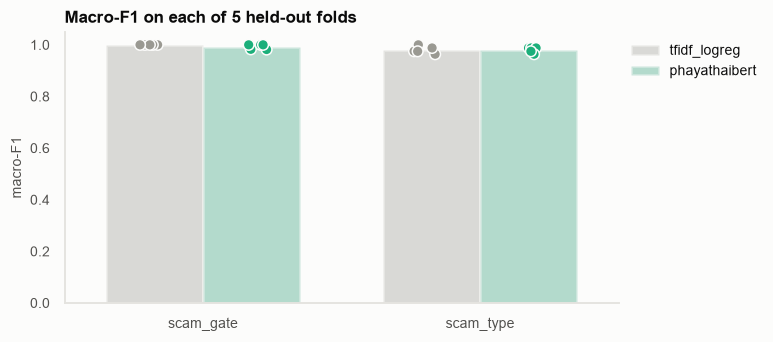

,task,model,mean,std,min,max
0,scam_gate,phayathaibert,0.993,0.010,0.982,1.000
1,scam_gate,tfidf_logreg,1.000,0.000,1.000,1.000
2,scam_type,phayathaibert,0.980,0.011,0.964,0.988
3,scam_type,tfidf_logreg,0.980,0.014,0.964,1.000


In [58]:
from sklearn.model_selection import StratifiedGroupKFold

N_FOLDS = 5
RUN_BERT_CV = True


def cross_validate(
    task: str, frame: pd.DataFrame, label_col: str, label_names: list[str], epochs: int
) -> pd.DataFrame:
    """Macro-F1 of each model on each held-out fold."""
    frame = frame.reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = [held_out for _, held_out in splitter.split(frame, frame[label_col], frame["group"])]
    ids = list(range(len(label_names)))
    rows = []
    for k, score_idx in enumerate(folds):
        fit_idx = np.setdiff1d(frame.index, score_idx)
        y_true = frame.loc[score_idx, label_col]
        baseline = make_baseline().fit(frame.loc[fit_idx, "text"], frame.loc[fit_idx, label_col])
        predictions = {"tfidf_logreg": baseline.predict(frame.loc[score_idx, "text"])}
        if RUN_BERT_CV:
            select_idx = folds[(k + 1) % N_FOLDS]
            train_idx = np.setdiff1d(fit_idx, select_idx)
            name = f"cv-{task}-fold{k + 1}"
            trainer = fine_tune(
                name,
                frame.loc[train_idx],
                frame.loc[select_idx],
                label_col,
                label_names,
                epochs,
                show=False,
            )
            predictions["phayathaibert"] = predict_ids(trainer, frame.loc[score_idx], label_col)
            del trainer
            torch.cuda.empty_cache()
            shutil.rmtree(CHECKPOINTS / name, ignore_errors=True)
        for model, y_pred in predictions.items():
            f1 = f1_score(y_true, y_pred, labels=ids, average="macro", zero_division=0)
            rows.append(
                {
                    "task": task,
                    "model": model,
                    "fold": k + 1,
                    "samples": len(score_idx),
                    "macro_f1": f1,
                }
            )
        print(f"{task}: fold {k + 1} of {N_FOLDS} done")
    return pd.DataFrame(rows)


cv_parts = [
    cross_validate(
        "scam_gate", pd.concat([data["train"], data["valid"]]), "gate", GATE_LABELS, epochs=6
    )
]
if TRAIN_TYPE_MODEL:
    cv_parts.append(
        cross_validate(
            "scam_type", pd.concat([typed["train"], typed["valid"]]), "type", TYPE_LABELS, epochs=10
        )
    )
cv_scores = pd.concat(cv_parts, ignore_index=True)

cv_models = [m for m in MODEL_COLORS if m in set(cv_scores["model"])]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
sns.barplot(
    data=cv_scores, x="task", y="macro_f1", hue="model", hue_order=cv_models, palette=MODEL_COLORS,
    errorbar=None, alpha=0.35, width=0.7, edgecolor=SURFACE, linewidth=2, ax=ax,
)  # fmt: skip
sns.stripplot(
    data=cv_scores, x="task", y="macro_f1", hue="model", hue_order=cv_models, palette=MODEL_COLORS,
    dodge=True, jitter=0.08, size=7, edgecolor=SURFACE, linewidth=1, legend=False, ax=ax,
)  # fmt: skip
ax.set(
    title=f"Macro-F1 on each of {N_FOLDS} held-out folds",
    xlabel="",
    ylabel="macro-F1",
    ylim=(0, 1.05),
)
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

cv_summary = (
    cv_scores.groupby(["task", "model"])["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
    .reset_index()
)
cv_summary.style.format(precision=3).bar(subset=["mean"], vmin=0, vmax=1, color="#b7d3f6")

## Step 13. Model evaluation on the test set

Both PhayaThaiBERT models are scored on the test set with the same `score` function as the
baseline. This is the score the spec asks for. Compare it with the cross-validation mean
from step 12: if the two are far apart, the test set is the less reliable one, because it
is smaller. The type score uses test samples that are scams of a trained type, so it measures the
type model alone and not the gate's mistakes.

The type model has no "other" answer. The histogram shows how sure it is on the `outside`
samples, scams of a type it never trained on. Every sample to the right of the dashed line
would get a type from `predict`, and that type is wrong by definition. If most of them are on
the right, raise `TYPE_MIN_CONFIDENCE` or collect data for the missing types.

The bar chart and the summary table hold the macro averages. Per-class numbers are in the
tables above them and in `models/scam_classifier_metrics.json`.

In [ ]:
score(
    "scam_gate", "phayathaibert", data["test"]["gate"], gate_test_pred, GATE_LABELS,
    data["test"]["source"],
)  # fmt: skip
if TRAIN_TYPE_MODEL:
    score(
        "scam_type", "phayathaibert", typed["test"]["type"], type_test_pred, TYPE_LABELS,
        typed["test"]["source"],
    )  # fmt: skip

# Scam samples outside the trained types: how many would still get a type?
outside_typed = None
if TRAIN_TYPE_MODEL and len(outside):
    outside_typed = int((outside_confidence >= TYPE_MIN_CONFIDENCE).sum())
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.hist(
        outside_confidence, bins=20, range=(0, 1), color=NEUTRAL, edgecolor=SURFACE, linewidth=1
    )
    ax.axvline(TYPE_MIN_CONFIDENCE, color=INK, linestyle="--", linewidth=1)
    ax.text(
        TYPE_MIN_CONFIDENCE,
        1.01,
        "gets a type from here",
        transform=ax.get_xaxis_transform(),
        color=INK,
        fontsize=9,
        va="bottom",
    )
    ax.set(
        title="Type model on scams outside its types",
        xlabel="highest type probability",
        ylabel="samples",
    )
    plt.show()
    print(
        f"{outside_typed} of {len(outside)} scam samples outside the trained types would get a type"
    )

metrics = {
    "model_id": MODEL_ID,
    "seed": SEED,
    "samples": {name: int(len(frame)) for name, frame in data.items()},
    "type_labels": TYPE_LABELS,
    "not_enough_data": NOT_ENOUGH_DATA,
    "cross_validation": {
        "folds": N_FOLDS,
        "pool": "train + valid",
        "macro_f1": cv_summary.to_dict(orient="records"),
    },
    "type_min_confidence": TYPE_MIN_CONFIDENCE,
    "outside_types": {"samples": int(len(outside)), "given_a_type": outside_typed},
    "gate_baseline_valid_f1_by_input": speaker_f1.round(4).to_dict(),
    "results": results,
}
MODELS.mkdir(parents=True, exist_ok=True)
(MODELS / "scam_classifier_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)

summary = (
    pd.DataFrame(results)
    .drop(columns=["per_class", "by_source"], errors="ignore")
    .sort_values(["task", "model"])
    .reset_index(drop=True)
)
print("not scored, not enough data:", NOT_ENOUGH_DATA)

f1 = (
    summary.pivot(index="task", columns="model", values="f1")
    .reindex(columns=list(MODEL_COLORS))
    .dropna(axis=1, how="all")
)
ax = f1.plot.bar(
    figsize=(6.5, 3.2), width=0.7, rot=0, edgecolor=SURFACE, linewidth=2,
    color=[MODEL_COLORS[m] for m in f1.columns],
)  # fmt: skip
label_bars(ax, "{:.2f}")
ax.set(title="Macro-F1 on the test set", xlabel="", ylabel="macro-F1", ylim=(0, 1.12))
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

summary.style.format(precision=3).bar(
    subset=["precision", "recall", "f1", "accuracy"], vmin=0, vmax=1, color="#b7d3f6"
)

### Extra evaluation: receiver outcome and hand-written outside test

The cells from here to step 14 were added after the original notebook. They only read what
steps 8 to 13 left behind (the baselines, `gate_test_pred`, `results`) and the two models
saved in `models/`, so the steps above run exactly as in the original.

- The first cell defines two helpers and reads the hand-written demo calls.
- Then: does the gate catch scams where the receiver goes along?
- Then: both models on the hand-written calls, an outside test.
- The last cell adds these numbers to `models/scam_classifier_metrics.json` and draws the
  macro-F1 of every task, hand-written included.

In [ ]:
# The hand-written demo calls, cleaned by the earlier version of this notebook (A:/B: text, labels
# mapped to the spec types). No model trains on them, so all of them are an outside test in step
# 13: calls written by people, not by the generator. This is the only place they are read.
HANDWRITTEN_FILE = ROOT / "data" / "processed" / "dataset.csv"
handwritten = handwritten_typed = None
HANDWRITTEN_TYPES: list[str] = []  # the trained types with enough hand-written calls to score
if HANDWRITTEN_FILE.exists():
    handwritten = read_records(HANDWRITTEN_FILE)
    handwritten["gate"] = handwritten["label_scam"].astype(int)
    handwritten_typed = handwritten[handwritten["label_type"].isin(TYPE_LABELS)].copy()
    handwritten_typed["type"] = handwritten_typed["label_type"].map(TYPE_LABELS.index)
    per_type = handwritten_typed["label_type"].value_counts()
    HANDWRITTEN_TYPES = [t for t in TYPE_LABELS if per_type.get(t, 0) >= MIN_TYPE_EVAL_SAMPLES]
    print(
        f"hand-written outside test: {len(handwritten)} calls, {int(handwritten['gate'].sum())} "
        f"scams; types scored: {HANDWRITTEN_TYPES}"
    )
else:
    print(f"no {HANDWRITTEN_FILE.relative_to(ROOT)}: the hand-written outside test is skipped")


def recall_by_outcome(frame: pd.DataFrame, pred) -> pd.DataFrame:
    """For the scam calls of frame, by scam_outcome and all together: how many there are, how many
    the gate caught and the recall. `pred` is the gate's answer (1 = scam) for every row of frame;
    normal calls are left out."""
    caught = pd.Series(np.asarray(pred) == 1, index=frame.index)
    scams = frame["label_scam"].astype(bool)
    outcome = frame["scam_outcome"].fillna("none")
    groups = {name: scams & (outcome == name) for name in ("scammed", "safe")}
    groups["all scams"] = scams
    rows = {}
    for name, rows_in in groups.items():
        n = int(rows_in.sum())
        rows[name] = {
            "calls": n,
            "caught": int(caught[rows_in].sum()),
            "recall": float(caught[rows_in].mean()) if n else float("nan"),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def macro_f1_over(y_true, y_pred, label_ids: list[int]) -> float:
    """Macro-F1 over the given classes only, so a class with no samples is not counted as 0."""
    from sklearn.metrics import f1_score

    return float(f1_score(y_true, y_pred, labels=label_ids, average="macro", zero_division=0))

### Does the gate catch scams where the receiver goes along?

`scam_outcome` says how each scam call ends: `scammed` (the receiver goes along) or `safe` (the
receiver refuses). The table counts, for each, how many test scams the gate caught. A clearly
lower recall on `scammed` means the model leans on how the receiver reacts ("they refused, so
it was a scam"), and it would miss real victims who cooperate. The speaker check in step 8
asks the same question from the other side.

The test set holds about 35 scams of each outcome, so one missed call moves recall by about 3
points. Read a gap of one or two calls as noise. The second table splits PhayaThaiBERT's
recall by type.

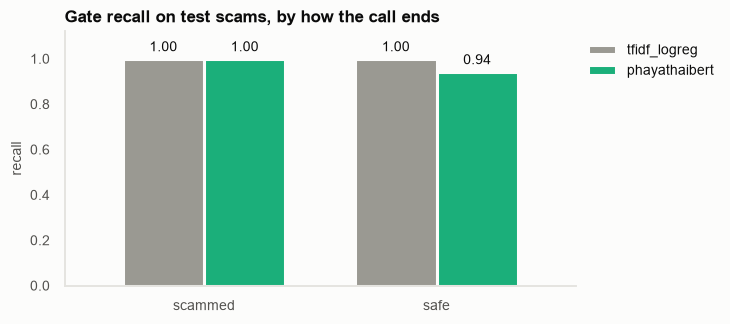

PhayaThaiBERT recall by type and outcome:
                scammed   safe  all scams
fake_authority      1.0  0.714      0.857
investment          1.0  1.000      1.000
lottery             1.0  1.000      1.000
phishing_otp        1.0  1.000      1.000
romance             1.0  1.000      1.000


tfidf_logreg               phayathaibert                 
                 calls caught recall         calls caught    recall
scammed             35     35    1.0            35     35  1.000000
safe                35     35    1.0            35     33  0.942857
all scams           70     70    1.0            70     68  0.971429

In [ ]:
# The baseline's test answers, as step 8 scored them.
gate_baseline_test_pred = gate_baseline.predict(data["test"]["text"])

outcome_recall = pd.concat(
    {
        "tfidf_logreg": recall_by_outcome(data["test"], gate_baseline_test_pred),
        "phayathaibert": recall_by_outcome(data["test"], gate_test_pred),
    },
    axis=1,
)

test = data["test"]
gate_pred = np.asarray(gate_test_pred)
recall_by_type = pd.DataFrame(
    {
        label_type: recall_by_outcome(test[rows], gate_pred[rows.to_numpy()])["recall"]
        for label_type in sorted(set(test.loc[test["label_scam"], "label_type"].dropna()))
        for rows in [test["label_type"] == label_type]
    }
).T

recall = outcome_recall.xs("recall", axis=1, level=1).loc[["scammed", "safe"]]
ax = recall.plot.bar(
    figsize=(6, 3), width=0.7, rot=0, edgecolor=SURFACE, linewidth=2,
    color=[MODEL_COLORS[m] for m in recall.columns],
)  # fmt: skip
label_bars(ax, "{:.2f}")
ax.set(title="Gate recall on test scams, by how the call ends", xlabel="", ylabel="recall",
       ylim=(0, 1.12))  # fmt: skip
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

print("PhayaThaiBERT recall by type and outcome:")
print(recall_by_type.round(3).to_string())
outcome_recall

### Hand-written calls: an outside test

The models never trained on the hand-written demo calls (`data/processed/dataset.csv`), so all
of them are a test written by people instead of the generator. The gate is scored on every call
with the same `score` function (task `scam_gate_handwritten`). The type models are scored on the
types in `HANDWRITTEN_TYPES`, the trained types with at least `MIN_TYPE_EVAL_SAMPLES`
hand-written calls; macro-F1 is taken over those types only.

Read it with three things in mind:

- The calls are written differently: hang-up notes and narration were removed, and in almost
  every scam the receiver refuses.
- A few labels are wrong, for example `call_00056`, a "Legit Bank Call" that asks for a
  transfer to a personal account.
- The gap between this score and the test set score is how much the models depend on the
  generator's way of writing. A small gap is the result to hope for.

In [ ]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer
from transformers import TrainingArguments


def load_for_prediction(model_dir: Path) -> Trainer:
    """A prediction-only Trainer on a model that `save` wrote (steps 10 and 11 free theirs)."""
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    args = TrainingArguments(
        output_dir=str(CHECKPOINTS / "predict"),
        per_device_eval_batch_size=32,
        fp16=device == "cuda",
        report_to="none",
    )
    return Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tokenizer))


# Answers on the hand-written calls, scored in the next cell.
gate_baseline_hw_pred = type_baseline_hw_pred = gate_hw_pred = type_hw_pred = None
if handwritten is not None:
    gate_baseline_hw_pred = gate_baseline.predict(handwritten["text"])
    reader = load_for_prediction(GATE_DIR)
    gate_hw_pred = predict_ids(reader, handwritten, "gate")
    del reader
    if TRAIN_TYPE_MODEL and len(handwritten_typed):
        type_baseline_hw_pred = type_baseline.predict(handwritten_typed["text"])
        reader = load_for_prediction(TYPE_DIR)
        type_hw_pred = predict_ids(reader, handwritten_typed, "type")
        del reader
    torch.cuda.empty_cache()

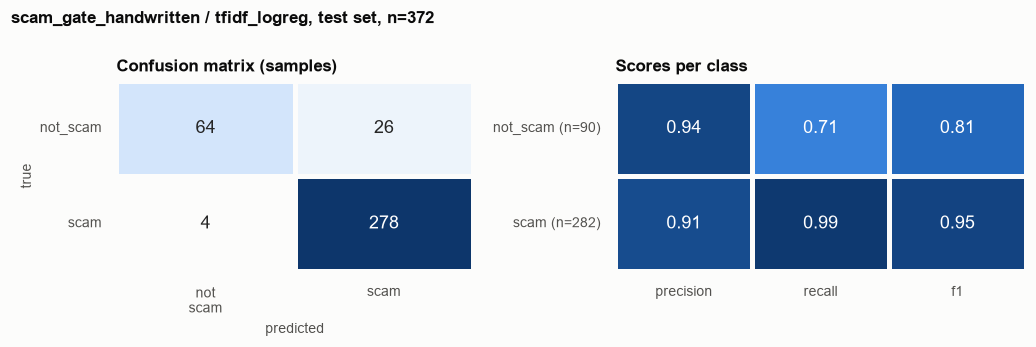

scam_gate_handwritten / tfidf_logreg: macro  P=0.928  R=0.848  F1=0.879  (95% interval for F1: 0.84 to 0.92)


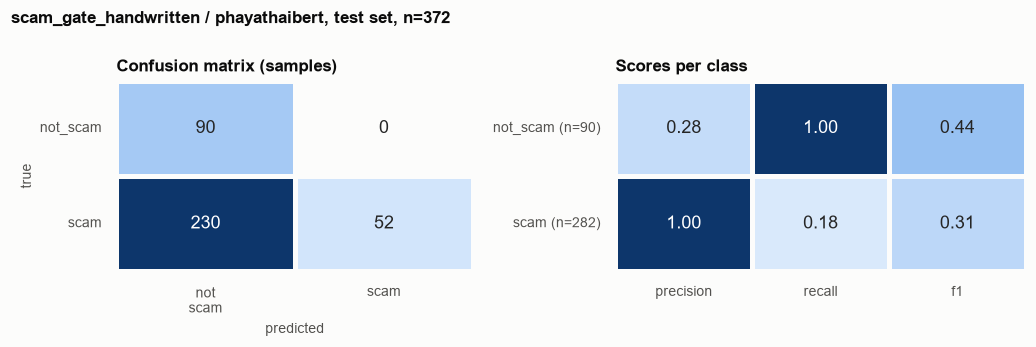

scam_gate_handwritten / phayathaibert: macro  P=0.641  R=0.592  F1=0.375  (95% interval for F1: 0.33 to 0.43)
type models on the hand-written calls (macro-F1 over the types scored):


tfidf_logreg                                  phayathaibert  \
                  precision  recall      f1 support macro_f1     precision   
fake_authority       0.7225  0.9318  0.8139   176.0   0.5065        0.7549   
investment           0.8000  0.2222  0.3478    18.0   0.5065        0.5455   
phishing_otp         0.6071  0.2537  0.3579    67.0   0.5065        0.4884   

                                                 
                recall      f1 support macro_f1  
fake_authority  0.8750  0.8105   176.0   0.5354  
investment      0.3333  0.4138    18.0   0.5354  
phishing_otp    0.3134  0.3818    67.0   0.5354

In [ ]:
handwritten_type_scores = None
handwritten_type_table = None
if handwritten is None:
    print("no hand-written file: the outside test is skipped")
else:
    for model, pred in (("tfidf_logreg", gate_baseline_hw_pred), ("phayathaibert", gate_hw_pred)):
        score("scam_gate_handwritten", model, handwritten["gate"], pred, GATE_LABELS)

    if TRAIN_TYPE_MODEL and HANDWRITTEN_TYPES:
        ids = [TYPE_LABELS.index(t) for t in HANDWRITTEN_TYPES]
        scored = handwritten_typed["label_type"].isin(HANDWRITTEN_TYPES).to_numpy()
        truth = handwritten_typed["type"].to_numpy(dtype=int)[scored]
        handwritten_type_scores = {}
        for model, pred in (
            ("tfidf_logreg", type_baseline_hw_pred),
            ("phayathaibert", type_hw_pred),
        ):
            guess = np.asarray(pred)[scored]
            p, r, f, n = precision_recall_fscore_support(truth, guess, labels=ids, zero_division=0)
            handwritten_type_scores[model] = {
                "per_class": {
                    t: {"precision": round(float(p[k]), 4), "recall": round(float(r[k]), 4),
                        "f1": round(float(f[k]), 4), "support": int(n[k])}
                    for k, t in enumerate(HANDWRITTEN_TYPES)
                },
                "macro_f1": round(macro_f1_over(truth, guess, ids), 4),
            }  # fmt: skip
        handwritten_type_table = pd.concat(
            {
                model: pd.DataFrame(s["per_class"]).T.assign(macro_f1=s["macro_f1"])
                for model, s in handwritten_type_scores.items()
            },
            axis=1,
        )
        print("type models on the hand-written calls (macro-F1 over the types scored):")
handwritten_type_table

not scored, not enough data: []


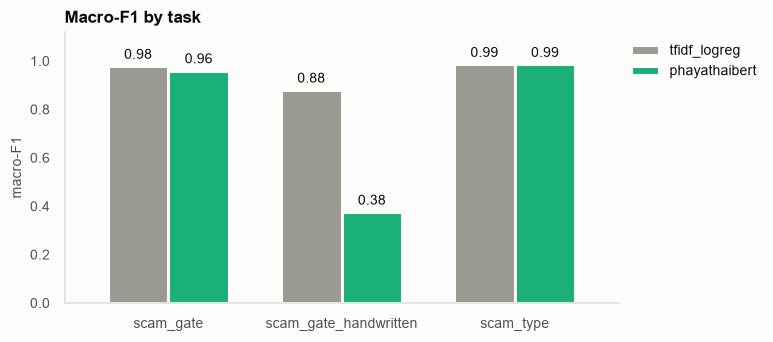

,task,model,precision,recall,f1,f1_ci_low,f1_ci_high,accuracy,n_test
0,scam_gate,phayathaibert,0.938,0.986,0.959,0.890,1.000,0.976,84
1,scam_gate,tfidf_logreg,0.993,0.964,0.978,0.918,1.000,0.988,84
2,scam_gate_handwritten,phayathaibert,0.641,0.592,0.375,0.326,0.426,0.382,372
3,scam_gate_handwritten,tfidf_logreg,0.928,0.849,0.879,0.838,0.920,0.919,372
4,scam_type,phayathaibert,0.987,0.986,0.986,0.949,1.000,0.986,70
5,scam_type,tfidf_logreg,0.987,0.986,0.986,0.949,1.000,0.986,70


In [ ]:
# Add the numbers of this section to the file the step 13 cell wrote.
metrics_path = MODELS / "scam_classifier_metrics.json"
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
metrics["gate_recall_by_outcome"] = {
    model: recall_by_outcome(data["test"], pred)
    .astype(object)
    .where(lambda f: f.notna(), None)
    .to_dict(orient="index")
    for model, pred in (
        ("tfidf_logreg", gate_baseline_test_pred),
        ("phayathaibert", gate_test_pred),
    )
}
metrics["handwritten"] = (
    None
    if handwritten is None
    else {
        "file": HANDWRITTEN_FILE.relative_to(ROOT).as_posix(),
        "samples": int(len(handwritten)),
        "scams": int(handwritten["gate"].sum()),
        "types_scored": HANDWRITTEN_TYPES,
        "gate": "see results, task scam_gate_handwritten",
        "type": handwritten_type_scores,
    }
)
metrics["results"] = results  # now with the scam_gate_handwritten rows
metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")

summary = (
    pd.DataFrame(results)
    .drop(columns=["per_class", "by_source"], errors="ignore")
    .sort_values(["task", "model"])
    .reset_index(drop=True)
)
print("not scored, not enough data:", NOT_ENOUGH_DATA)

f1 = (
    summary.pivot(index="task", columns="model", values="f1")
    .reindex(columns=list(MODEL_COLORS))
    .dropna(axis=1, how="all")
)
ax = f1.plot.bar(
    figsize=(6.5, 3.2), width=0.7, rot=0, edgecolor=SURFACE, linewidth=2,
    color=[MODEL_COLORS[m] for m in f1.columns],
)  # fmt: skip
label_bars(ax, "{:.2f}")
ax.set(title="Macro-F1 by task", xlabel="", ylabel="macro-F1", ylim=(0, 1.12))
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

summary.style.format(precision=3).bar(
    subset=["precision", "recall", "f1", "accuracy"], vmin=0, vmax=1, color="#b7d3f6"
)

## Step 14. Inference

`ScamClassifier.predict` has the signature of the `ScamClassifier` protocol in
`nlp_core/interfaces.py`: it returns `(label_scam, label_type, confidence)`.

- If the gate's top probability is below `GATE_MIN_CONFIDENCE`, the answer is
  `(True, None, 0.0)`. An unsure answer is never treated as safe.
- `label_type` is filled only when the gate says scam and the type model is at least
  `TYPE_MIN_CONFIDENCE` sure.

Both thresholds are starting values. Tune them on valid before the model goes into the app.

In [ ]:
GATE_MIN_CONFIDENCE = 0.60  # TYPE_MIN_CONFIDENCE is set at the start of part B


class ScamClassifier:
    def __init__(self, gate_dir: Path, type_dir: Path | None = None):
        self.tokenizer = AutoTokenizer.from_pretrained(gate_dir)
        self.gate = AutoModelForSequenceClassification.from_pretrained(gate_dir).to(device).eval()
        self.type = None
        if type_dir is not None:
            self.type = (
                AutoModelForSequenceClassification.from_pretrained(type_dir).to(device).eval()
            )

    @torch.no_grad()
    def _probabilities(self, model, text: str) -> torch.Tensor:
        text = to_model_text(normalize_text(text))
        inputs = self.tokenizer(
            text, truncation=True, max_length=MAX_LENGTH, return_tensors="pt"
        ).to(device)
        return model(**inputs).logits.float().softmax(dim=-1)[0].cpu()

    def predict(self, text: str) -> tuple[bool, str | None, float]:
        gate = self._probabilities(self.gate, text)
        confidence = float(gate.max())
        if confidence < GATE_MIN_CONFIDENCE:
            return True, None, 0.0
        is_scam = self.gate.config.id2label[int(gate.argmax())] == "scam"
        label_type = None
        if is_scam and self.type is not None:
            types = self._probabilities(self.type, text)
            if float(types.max()) >= TYPE_MIN_CONFIDENCE:
                label_type = self.type.config.id2label[int(types.argmax())]
        return is_scam, label_type, confidence


classifier = ScamClassifier(GATE_DIR, TYPE_DIR)

examples = [
    "A: สวัสดีครับ ผมร้อยตำรวจเอกจากกองปราบ บัญชีของคุณพัวพันคดีฟอกเงิน\nB: ผมไม่เคยทำอะไรแบบนั้นนะครับ\nA: ต้องโอนเงินมาให้ตรวจสอบภายในวันนี้ ห้ามวางสายและห้ามบอกใคร",
    "A: สวัสดีค่ะ โทรจากคลินิกทันตกรรมค่ะ ขอยืนยันนัดขูดหินปูนวันเสาร์สิบโมง\nB: ได้ค่ะ ไปตามนัดค่ะ\nA: ขอบคุณค่ะ แล้วพบกันวันเสาร์นะคะ",
]
for text in examples:
    print(classifier.predict(text), "<-", text.splitlines()[0])

### Hand-written demo calls

One call of each type from the hand-written outside test (`data/processed/dataset.csv`),
through the same `classifier`. None of them is in the training, valid or test split.

In [ ]:
handwritten_examples = [
    # 1. Romance (call_00223, originally 'Romance Scam')
    "A: สวัสดีครับ น้องเอ๋ยินดีด้วยนะ ที่บอกว่าจะส่งของขวัญวันเกิดให้ ตอนนี้ของติดอยู่ที่ศุลกากรเข้ามาไม่ได้ ต้องจ่ายค่าภาษี 8,000 บาท ก่อนนะครับ\nB: อ้าว พี่เคนเหรอคะ แต่วันเกิดฉันยังไม่ถึงนะคะ แล้วทำไมต้องโอนเงินเข้าบัญชีคุณล่ะคะ\nA: เพราะผมฝากเข้าบัญชีเจ้าหน้าที่ไว้ครับ รีบโอนมาเลย\nB: พี่เคนไม่เคยพูดจาแบบนี้ ฉันว่าฉันจะบล็อคเบอร์นี้ดีกว่าค่ะ",
    # 2. Investment (call_00282, originally 'Dividend Scam')
    "A: สวัสดีค่ะ ติดต่อคุณเรื่องบัญชีลงทุนเก่าที่ปิดแล้ว ค่ะ ระบบขึ้นสถานะเร่งด่วน ต้องยืนยันข้อมูลก่อนปิดรอบ\nB: ฟังดูแปลก ๆ นะคะ ฉันไม่ได้ดำเนินการอะไรไว้\nA: ผมช่วยจัดการให้ได้ แต่ต้องบอกเลขบัตรและรหัสที่ส่งเข้าโทรศัพท์ก่อน ห้ามวางสายเพราะรายการจะค้าง\nB: ผมจะไม่กดลิงก์และไม่บอกรหัสใด ๆ ขอไปตรวจสอบกับสำนักงานด้วยตัวเองครับ\nA: อย่าบอกใครเด็ดขาดครับ!\nB: การห้ามตรวจสอบยิ่งทำให้ไม่น่าเชื่อถือ ผมจะรายงานเบอร์นี้",
    # 3. Phishing OTP (call_00214, originally 'E-commerce Phishing')
    "A: สวัสดีครับ ขอสายคุณเอ็มได้ไหมครับ\nB: คือผมเอง มีอะไรครับ\nA: พอดีทาง Shopee มีการสั่งซื้อสินค้ารอบใหญ่ ทางระบบตรวจสอบพบว่าบัญชีของคุณมีการทำรายการผิดปกติครับ รบกวนแจ้งเลข OTP ที่ได้รับมาเพื่อยืนยันว่าเป็นเจ้าของบัญชีจริงนะครับ\nB: อ้าว แต่ผมไม่ได้สั่งของนะครับ แล้วทำไมต้องขอ OTP ด้วย\nA: เพื่อยกเลิกการทำรายการให้คุณไงครับ รีบเลขมาเลยไม่งั้นเงินจะหาย\nB: เดี๋ยวผมโทรไปสายด่วน Shopee เองดีกว่าครับ\nA: อย่าพึ่งวางสาย...",
    # 4. Fake Authority (call_00012, originally 'Government Official Impersonation')
    "A: สวัสดีค่ะ คุณมาลีใช่ไหมคะ ดิฉันโทรมาจากกรมที่ดิน มีเรื่องเกี่ยวกับที่ดินโครงการของคุณ\nB: อ๋อ มีอะไรหรือคะ\nA: มีคนมาขอใบเปลี่ยนชื่อกรรมการในโฉนดที่ดินของคุณ ทางเราต้องการยืนยัน รบกวนแจ้งเลขบัตรประชาชนและเลขที่บัญชีออมทรัพย์ด้วย\nB: เปลี่ยนชื่อกรรมการเหรอ ฉันไม่ได้ทำนะ\nA: ถ้างั้นระบบต้องสั่งระงับการทำพินัยกรรมชั่วคราว ต้องโอนค่าธรรมเนียม 2,000 บาทมาก่อน\nB: 2,000 บาท โอนเข้าบัญชีอะไรคะ\nA: บัญชี ด.ข. สมชาย ธนาคารออมสิน ค่ะ\nB: บัญชีส่วนตัวเหรอ ฉันว่าฉันจะไปที่สำนักงานกรมที่ดินเองดีกว่าค่ะ",
    # 5. Lottery (call_00005, originally 'Lottery/Prize Scam')
    "A: อ้าว คุณสมปองเองเหรอครับ ยินดีด้วยนะครับ ท่านได้รับรางวัลที่ 1 จากการจับรางวัลหวยรัฐบาล 100,000 บาท!\nB: จริงเหรอครับ! ผมไม่ได้ซื้อหวยนะ\nA: ท่านเป็นสมาชิกแอปกระเป๋าเงินของเรา ทางเราจะโอนเงินให้ แต่ต้องหักภาษี 10% ท่านต้องโอนเงิน 10,000 บาท มาที่บัญชีเราก่อน\nB: โอนก่อนเหรอครับ ปกติไม่น่าต้องหักจากตัวเงินรางวัลเลยเหรอ\nA: นี่เป็นระบบของกรมสรรพากรเลยครับ ต้องจ่ายก่อน\nB: ผมไม่มั่นใจ ผมว่าผมจะติดต่อสายด่วนกรมสรรพากรดูก่อนนะครับ",
    # 6. Normal call (call_00272, originally 'Legit Bank Call')
    "A: สวัสดีค่ะ โทรกลับตามคำขอเรื่องแจ้งการเปลี่ยนแปลงสาขานะคะ\nB: ค่ะ ฉันกำลังเดินทาง ขอทราบเลขอ้างอิงไว้ก่อน\nA: ได้ค่ะ เลขอ้างอิงอยู่ในข้อความแจ้งเตือนเดิม คุณตรวจสอบในแอปทางการได้เลย\nB: ดีค่ะ ฉันจะเปิดแอปเอง ไม่ต้องส่งลิงก์มา\nA: ได้เลยค่ะ ไม่ต้องบอกรหัสหรือชำระเงินใด ๆ\nB: ฉันจะจดวันเวลาไว้และตรวจสอบผ่านช่องทางทางการ หมายเลขรายการ 277",
]
for text in handwritten_examples:
    print(classifier.predict(text), "<-", text.splitlines()[0])

## Limitations

- The data is generated and small. The test set has a few dozen samples, so one wrong answer
  moves a class score by several points. Use these as demo numbers.
- Cross-validation and the bootstrap interval show how much a score can move. They do not
  fix the data: every fold comes from the same templates, so all folds share the same
  shortcuts.
- If PhayaThaiBERT and the baseline score the same on a task, the fine-tuned model has not
  shown it is better. On a test set this small, a gap of two or three samples is not a result.
- A type is scored only if it has `MIN_TYPE_EVAL_SAMPLES` samples in valid and in test. The
  table at the start of part B lists the types that are left out, and step 4 shows how many
  samples each type is short of the spec target of 150.
- The type model cannot answer "none of these". Step 13 shows how many scams outside its
  types would still get a type.
- In almost every scam sample the receiver notices the scam and refuses. The chart after
  step 8 shows how far the receiver's turns alone get. Real victims often go along, so new
  scam data should include calls where the receiver complies, and new normal data should
  include receivers who are careful with a real caller.
- After the narration is removed, many scam samples share a template and differ only in the
  topic. The type label then depends on a few words, and some identical texts had different
  types in the spreadsheet (step 4 prints and drops them).
- Grouping stops at `NEAR_DUPLICATE_SIMILARITY`. Test samples can still share a looser
  template with train samples below that line, so the scores are higher than they would be
  on calls written from scratch.
- A few caller lines still use words a scammer would not say, such as `ปลอม`. They are left
  in because removing them by rule would damage normal sentences.
- Simulated calls come from a few dozen scenarios, and every scenario stays in one split. A
  score on them says how well the model reads one scenario it has not seen, not how well it
  reads real calls. With 4 to 6 scenarios for each type and one scenario in one split,
  the type model gets few distinct scenarios to learn from, and a type can run short of valid
  or test samples. With `KEEP_ORIGINAL_TEST` the test set stays the hand-written one, so
  scores stay comparable with older runs.
- The LLM classifier is not scored here. The spec's three-way comparison needs it run on the
  same `data/processed/test.csv`.

When the dataset grows, set `REBUILD_SPLIT = True` and rerun the notebook. New type names must be
added to `TYPE_MAP` in step 4. If the layout of the file changes, edit the input format cell
at the start of part A. The cleaning rules there (`BRACKET_NOTE`, `STAGE_NOTE`, `NARRATION`)
were written for this demo file, so run the step 2 check again on the new data and adjust them. Changing the split makes older scores incomparable, so
rerun every model after a rebuild.